# Capstone — Which pages should an editor review first? A time-aware decline-risk queue

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Thallysson100/FlyRank_AI/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

**Lane:** Refresh / Content Opportunity Scoring (same lane as w01–w05).
**Data:** full FlyRank pseudonymized warehouse release (`v20260703`), queried with DuckDB over `hf://` — the 79M-row daily fact table is scanned **once**, aggregated to page × month, and cached locally.

This notebook mirrors the research paper section by section. Every result the paper shows (tables, charts, headline numbers) is written to `work/outputs/capstone/` so the PDF builder can read it later without re-running any model.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## Abstract

*Which visible pages should a content editor review first, before they lose search visibility?* Using the FlyRank pseudonymized warehouse release (78.8M daily rows, 27 Jan 2025 → 30 Jun 2026), I built a monthly page × decision-date panel and labelled a page as *declining* when its next-month daily impressions fell more than 20% below the median page of its own site — so site-wide shocks are not mistaken for page decay. A histogram gradient-boosting model that only sees information available at the decision date was selected on May 2026 and evaluated **once** on a sealed June 2026 month (89,237 pages, base rate 39.6%): PR-AUC **0.724** vs **0.683** for the best transparent momentum rule (gap +0.041, 95% client-bootstrap CI +0.021 to +0.067), while an impact-ordered version of the same score covers **66%** of site-relative lost impressions in its top 10% of pages. The output is a ranked, reason-coded review queue for **decision support**; it does not show that refreshing a page causes recovery, and on never-seen clients the advantage over the simple rule shrinks to +0.013 PR-AUC.

*(Written last, placed first. Every number here is regenerated in `work/outputs/capstone/capstone_results.json`.)*

## 0. Setup

Repo root detection, output folders, a fixed random seed, and an authenticated DuckDB connection. The Hugging Face READ token comes from the environment (`HF_TOKEN`), a local `.env` file, Colab Secrets, or a `getpass` prompt — it is **never** written into a cell.

In [1]:
import os, sys, json, time, getpass, warnings
import numpy as np
import pandas as pd
import duckdb
import matplotlib
import matplotlib.pyplot as plt
import sklearn

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

# --- repo root (works from work/notebooks/ or from the root) ---
root = os.getcwd()
while not os.path.isdir(os.path.join(root, "skills")) and os.path.dirname(root) != root:
    root = os.path.dirname(root)
os.chdir(root)

OUT = "work/outputs/capstone"          # everything the paper/PDF needs lands here
FIG = f"{OUT}/figures"
TAB = f"{OUT}/tables"
CACHE = f"{OUT}/cache"                 # parquet caches (gitignored: *.parquet)
for d in (OUT, FIG, TAB, CACHE):
    os.makedirs(d, exist_ok=True)

# --- token: env var -> .env -> Colab secret -> prompt ---
token = os.environ.get("HF_TOKEN")
if not token and os.path.exists(".env"):
    for line in open(".env"):
        if line.strip().startswith("HF_TOKEN="):
            token = line.split("=", 1)[1].strip().strip('"').strip("'")
if not token and "google.colab" in sys.modules:
    from google.colab import userdata
    token = userdata.get("HF_TOKEN")
if not token:
    token = getpass.getpass("Hugging Face READ token: ")

con = duckdb.connect()
con.execute(f"CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '{token}')")
del token

REL = "hf://datasets/FlyRank/internship-warehouse"
T = {
    "dim_clients": f"read_parquet('{REL}/dim_clients.parquet')",
    "dim_content": f"read_parquet('{REL}/dim_content.parquet')",
    "fact_daily_month": lambda m: f"read_parquet('{REL}/fact_content_daily_performance/month={m}/*.parquet')",
}

# results registry: every headline number the paper quotes is stored here and dumped to JSON
RESULTS = {"seed": SEED, "release": "flyrank_pseudonymized_warehouse_release_v20260703"}
def save_results():
    with open(f"{OUT}/capstone_results.json", "w") as f:
        json.dump(RESULTS, f, indent=2, default=str)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
COLORS = {"model": "#2F6DB5", "logit": "#7FA7D9", "momentum": "#E08A2E", "volume": "#9A9A9A", "random": "#CCCCCC"}

print("root:", root)
print(f"duckdb {duckdb.__version__} | sklearn {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__}")
print("outputs ->", OUT)

root: /home/thallysson/AreaDeTrabalho/FlyRank_AI
duckdb 2.0.0 | sklearn 1.9.1 | pandas 3.1.1 | numpy 2.5.4
outputs -> work/outputs/capstone


## 1. Question

**Research question.** *At the end of a month, using only what is already observable, which visible pages are most at risk of losing a meaningful share of their search impressions next month — and what should an editor look at first?*

**The decision it supports.** A content/SEO editor has limited review hours each month. They need a **ranked review queue**: which pages to open first, with a suggested action (refresh, protect, metadata review, prune/merge review, monitor), a reason code and a confidence label. The output is **decision support** for a human reviewer — not an automated edit, and not a claim that a refresh *will* recover traffic.

| Item | Choice |
|---|---|
| Unit of analysis (one row) | one content page × one monthly decision date *T* (last day of a month) |
| Prediction | P(page's daily impressions next month fall > 20% below its 3-month average) |
| Output | ranked queue + action + reason codes + confidence |
| Cost of a false positive | an editor spends review time on a page that was fine |
| Cost of a false negative | a sliding page with real demand is not reviewed, loss continues |
| Capacity assumption | an editor reviews ~20–100 pages per cycle → evaluate Precision@20/50/100 |

**What changed vs. my weekly notebooks.** w01–w05 framed the same lane, but the w05 model was trained on one fixed window from the query table and its label required `impressions_prev30 ≥ 300` while `impressions_prev30` was also a feature. The model could learn the eligibility filter itself, which is why ROC-AUC reached 0.995 — an inflated number. Here the eligibility rule **filters the population** instead of being part of the label, the windows come from the daily fact table at many decision dates, and the last month is a sealed test month.

The thresholds below are **policy choices**, written down once and stored with the results so every number in the paper traces back to them.

In [2]:
CONFIG = {
    "feature_window_months": 3,          # months observed before decision date T
    "label_window_months": 1,            # the month right after T
    "decline_ratio": 0.80,               # decline = next-month imp/day < 0.80 x 3-month avg imp/day
    "min_impressions_feature_window": 300,  # >= 100 impressions/month on average -> "visible page"
    "min_active_months": 3,              # impressions in each of the 3 feature months (persistence, not a blip)
    "min_page_age_days": 90,             # page existed for the whole feature window
    "val_label_month": "2026-05",        # model selection month
    "test_label_month": "2026-06",       # SEALED: evaluated once, at the end
    "live_decision_date": "2026-06-30",  # the queue we hand to editors (predicts July 2026)
    "top_k": [20, 50, 100, 500],
}
RESULTS["config"] = CONFIG
save_results()
pd.Series(CONFIG).to_frame("value")

,value
feature_window_months,3
label_window_months,1
decline_ratio,0.8
min_impressions_feature_window,300
min_active_months,3
min_page_age_days,90
val_label_month,2026-05
test_label_month,2026-06
live_decision_date,2026-06-30
top_k,"[20, 50, 100, 500]"


## 2. Data

**Release:** `FlyRank/internship-warehouse`, build `v20260703` (export 2026-07-03, daily facts cut at 2026-06-30).
**Tables used:** `dim_clients` (history coverage), `dim_content` (page metadata), `fact_content_daily_performance` (all 18 monthly partitions, 2025-01-27 → 2026-06-30).
**Table not used:** `fact_content_query_90d` — its fixed window (2026-04-02 → 2026-06-30) overlaps the sealed test month and exists for only one decision date, so it cannot produce leakage-free features for the earlier training months.

### 2.1 Sanity counts first (metadata-cheap)
Before any modeling: confirm row counts and date ranges match the published release numbers (104 clients, 519,606 content items, 78,835,655 daily rows).

In [3]:
con.execute("SET memory_limit='2GB'; SET threads=4; SET preserve_insertion_order=false;")

MONTHS = [str(p)[:7] for p in pd.period_range("2025-01", "2026-06", freq="M")]

dims = con.sql(f"""
    SELECT 'dim_clients' AS tbl, COUNT(*) AS n_rows FROM {T['dim_clients']}
    UNION ALL
    SELECT 'dim_content', COUNT(*) FROM {T['dim_content']}
""").df()

PART_CSV = f"{TAB}/data_partitions.csv"
rows = []
for m in ([] if os.path.exists(PART_CSV) else MONTHS):   # cached after the first run
    r = con.execute(f"SELECT COUNT(*) n, MIN(report_date) d0, MAX(report_date) d1 FROM {T['fact_daily_month'](m)}").fetchall()[0]
    rows.append({"month": m, "n_rows": r[0], "min_date": r[1], "max_date": r[2]})
part = pd.DataFrame(rows) if rows else pd.read_csv(PART_CSV)

print(dims.to_string(index=False))
print(f"\nDaily fact partitions: {len(part)} | total rows = {part.n_rows.sum():,} | "
      f"{part.min_date.min()} -> {part.max_date.max()}")
assert part.n_rows.sum() == 78_835_655, "row count does not match the published release"
assert dict(zip(dims.tbl, dims.n_rows)) == {'dim_clients': 104, 'dim_content': 519_606}
part.to_csv(PART_CSV, index=False)
RESULTS["data_counts"] = {"dim_clients": 104, "dim_content": 519_606,
                          "fact_daily_rows": int(part.n_rows.sum()),
                          "date_min": str(part.min_date.min()), "date_max": str(part.max_date.max())}
save_results()
part

        tbl  n_rows
dim_content  519606
dim_clients     104

Daily fact partitions: 18 | total rows = 78,835,655 | 2025-01-27 -> 2026-06-30


,month,n_rows,min_date,max_date
0,2025-01,1297,2025-01-27,2025-01-31
1,2025-02,75985,2025-02-01,2025-02-28
2,2025-03,167859,2025-03-01,2025-03-31
3,2025-04,285114,2025-04-01,2025-04-30
4,2025-05,349923,2025-05-01,2025-05-31
5,2025-06,329201,2025-06-01,2025-06-30
6,2025-07,469794,2025-07-01,2025-07-31
7,2025-08,704962,2025-08-01,2025-08-31
8,2025-09,845813,2025-09-01,2025-09-30
9,2025-10,2165471,2025-10-01,2025-10-31


**Reading the counts.** All three tables reconcile exactly with the published release (104 clients, 519,606 content items, 78,835,655 daily rows, 2025-01-27 → 2026-06-30). The panel is strongly **unbalanced in time**: the first ten months together hold < 7% of all rows, and volume jumps from ~2M rows in Oct-2025 to ~7–12M rows/month from Nov-2025 on (many clients started tracking around then). So most usable decision dates fall in 2026, and any training month before Nov-2025 rests on a handful of clients — we will see this directly in the per-month row counts of the panel.

### 2.2 One full scan: daily facts → page × month (cached)
Following the *aggregate-then-model* rule: each monthly partition is read once over `hf://`, reduced inside DuckDB to one row per page per month, and written to a local parquet cache. Reruns read the cache and never touch the remote host (no HTTP 429).

Grain guards and flag rules applied inside the SQL:
- grain probe: `(report_date, content_hash_id)` must be unique (checked on every partition);
- position is the **impression-weighted** average: `SUM(gsc_sum_position) / SUM(gsc_impressions)`;
- GA4 metrics are summed **only** on rows with `ga4_data_available IS TRUE` (three-valued flag; zero-filled rows before a client's GA4 start are not "no engagement");
- `imp_h2` = impressions in days 16..end of the month, used for a within-month momentum feature.

In [4]:
PM_SQL = """
SELECT
    content_hash_id,
    ANY_VALUE(client_hash_id)                                         AS client_hash_id,
    '{m}'                                                             AS month,
    COUNT(*)                                                          AS n_rows,
    SUM(gsc_impressions)                                              AS imp,
    SUM(gsc_clicks)                                                   AS clk,
    SUM(gsc_sum_position)                                             AS sum_pos,
    COUNT(*) FILTER (WHERE gsc_impressions > 0)                       AS active_days,
    COALESCE(SUM(gsc_impressions) FILTER (WHERE day(report_date) >= 16), 0) AS imp_h2,
    COUNT(*) FILTER (WHERE ga4_data_available IS TRUE)                AS ga4_days,
    SUM(ga4_sessions)             FILTER (WHERE ga4_data_available IS TRUE) AS sessions,
    SUM(ga4_engaged_sessions)     FILTER (WHERE ga4_data_available IS TRUE) AS engaged_sessions,
    SUM(ga4_total_engagement_sec) FILTER (WHERE ga4_data_available IS TRUE) AS engagement_sec,
    SUM(sessions_organic)         FILTER (WHERE ga4_data_available IS TRUE) AS sessions_organic,
    SUM(sessions_ai)              FILTER (WHERE ga4_data_available IS TRUE) AS sessions_ai,
    SUM(scroll_events)            FILTER (WHERE ga4_data_available IS TRUE) AS scroll_events
FROM {rel}
GROUP BY content_hash_id
"""

DUP_JSON = f"{CACHE}/grain_duplicates.json"
dup_log = json.load(open(DUP_JSON)) if os.path.exists(DUP_JSON) else {}
t0 = time.time()
for m in MONTHS:
    path = f"{CACHE}/page_month_{m}.parquet"
    if os.path.exists(path):
        continue
    rel = T["fact_daily_month"](m)
    for attempt in range(4):                       # polite retry on HTTP 429 / transient errors
        try:
            dup = con.execute(f"""SELECT COUNT(*) AS keys, COALESCE(SUM(n) - COUNT(*), 0) AS extra_rows,
                                         COALESCE(SUM((nd > 1)::INT), 0) AS conflicting
                                  FROM (SELECT report_date, content_hash_id, COUNT(*) n,
                                               COUNT(DISTINCT (gsc_impressions, gsc_clicks, ga4_sessions)) nd
                                        FROM {rel} GROUP BY ALL HAVING COUNT(*) > 1)""").fetchall()[0]
            dup_log[m] = {"dup_keys": int(dup[0]), "extra_rows": int(dup[1]), "conflicting_keys": int(dup[2])}
            assert dup[2] == 0, f"{m}: duplicated keys with DIFFERENT values -> needs a real rule"
            if dup[0] > 0:   # exact duplicates only -> drop them
                rel = f"(SELECT DISTINCT * FROM {rel})"
            con.execute(f"COPY ({PM_SQL.format(m=m, rel=rel)}) TO '{path}' (FORMAT parquet)")
            break
        except duckdb.Error as e:
            print(f"{m}: attempt {attempt+1} failed ({str(e)[:80]}...), waiting 60s")
            time.sleep(60)
    json.dump(dup_log, open(DUP_JSON, "w"))
    print(f"{m} cached ({time.time()-t0:.0f}s elapsed)")

PM = f"read_parquet('{CACHE}/page_month_*.parquet')"
recon = con.sql(f"SELECT month, SUM(n_rows) AS n_rows, COUNT(*) AS pages, SUM(imp) AS impressions, "
                f"COUNT(DISTINCT client_hash_id) AS clients FROM {PM} GROUP BY month ORDER BY month").df()
recon = recon.merge(part[["month", "n_rows"]], on="month", suffixes=("", "_published"))
recon["dup_rows_dropped"] = recon.month.map(lambda m: dup_log.get(m, {}).get("extra_rows", 0))
assert (recon.n_rows + recon.dup_rows_dropped == recon.n_rows_published).all(), "cache does not reconcile"
n_dup = int(recon.dup_rows_dropped.sum())
print(f"grain probe: {n_dup:,} exact duplicate daily rows found and dropped "
      f"({ {m: v for m, v in dup_log.items() if v['dup_keys']} })")
print(f"cache reconciles: {recon.n_rows.sum():,} unique daily rows (+{n_dup:,} duplicates) "
      f"-> {recon.pages.sum():,} page-month rows")
RESULTS["data_counts"]["exact_duplicate_rows_dropped"] = n_dup
save_results()
recon.drop(columns="n_rows_published").to_csv(f"{TAB}/data_monthly_volume.csv", index=False)
recon.drop(columns="n_rows_published")

grain probe: 6,390 exact duplicate daily rows found and dropped ({'2026-06': {'dup_keys': 6390, 'extra_rows': 6390, 'conflicting_keys': 0}})
cache reconciles: 78,829,265.0 unique daily rows (+6,390 duplicates) -> 2,871,202 page-month rows


,month,n_rows,pages,impressions,clients,dup_rows_dropped
0,2025-01,1297.0,476,13853.0,2,0
1,2025-02,75985.0,5903,1195015.0,3,0
2,2025-03,167859.0,10374,3847103.0,4,0
3,2025-04,285114.0,13046,8843940.0,4,0
4,2025-05,349923.0,14887,14454515.0,4,0
5,2025-06,329201.0,16399,16930659.0,9,0
6,2025-07,469794.0,27945,20298448.0,16,0
7,2025-08,704962.0,37204,29289942.0,15,0
8,2025-09,845813.0,53127,37726329.0,23,0
9,2025-10,2165471.0,110339,55073098.0,31,0


**Reading the scan.** The grain probe caught a real data-quality issue: **6,390 exact duplicate daily rows** in the June-2026 partition (355 pages, 13–30 June; every duplicated key carries identical values). They are dropped with `SELECT DISTINCT`; had they been kept, June impressions for those pages would be double-counted — and June is our sealed test month. After de-duplication, 78,829,265 unique daily rows collapse to 2.87M page-month rows that the rest of the notebook reads locally.

Two observations matter for the design:
1. Total impressions peak in Mar–Apr 2026 (~280–290M/month) and then fall to 266M (May) and 216M (June) while the number of tracked pages keeps growing. A **panel-wide drop** in the test month means the base rate of "decline" will be higher in June than in the training months — the model must rank well under a shifted base rate, and client-level trend features are needed to separate *site-wide* movement from *page-specific* decline.
2. Before Nov-2025 there are fewer than 32 clients per month. Early decision dates are kept (more history is good), but they contribute few rows.

### 2.3 Client coverage and the eligibility funnel
A decline label is only meaningful when the client's search tracking was live in **all four months** involved (three feature months + the label month). Otherwise "no impressions" may mean "no tracking". This is checked from observed data (client impressions > 0 in every month), and cross-checked against `dim_clients.gsc_data_start`.

In [5]:
# month index + days per month, so windows are integer arithmetic and rates are per day
months_df = pd.DataFrame({"month": MONTHS + ["2026-07"]})
months_df["mi"] = range(len(months_df))
months_df["days"] = [pd.Period(m).days_in_month for m in months_df.month]
months_df.loc[months_df.month == "2025-01", "days"] = 5          # panel starts 2025-01-27
con.register("months_df", months_df)

con.execute(f"""
CREATE OR REPLACE TABLE pm AS
SELECT p.*, m.mi, m.days FROM {PM} p JOIN months_df m USING (month)
""")
con.execute("""
CREATE OR REPLACE TABLE client_month AS
SELECT client_hash_id, mi, SUM(imp) AS c_imp, SUM(clk) AS c_clk, COUNT(*) AS c_pages
FROM pm GROUP BY ALL
""")

clients = con.sql(f"SELECT * FROM {T['dim_clients']}").df()
cov = con.sql("""SELECT client_hash_id, MIN(mi) FILTER (WHERE c_imp > 0) AS first_mi,
                        MAX(mi) FILTER (WHERE c_imp > 0) AS last_mi,
                        COUNT(*) FILTER (WHERE c_imp > 0) AS months_with_imp
                 FROM client_month GROUP BY 1""").df()
cov = cov.merge(clients[["client_hash_id", "access_profile", "gsc_data_start"]], on="client_hash_id", how="left")
cov["first_month_obs"] = cov.first_mi.map(dict(zip(months_df.mi, months_df.month)))
cov["gsc_start_month"] = pd.to_datetime(cov.gsc_data_start).dt.strftime("%Y-%m")

n_fact_clients = cov.client_hash_id.nunique()
n_with_imp = cov.first_mi.notna().sum()
gap_clients = (cov.months_with_imp < (cov.last_mi - cov.first_mi + 1)).sum()
agree = (cov.first_month_obs == cov.gsc_start_month).mean()
print(f"clients in daily facts: {n_fact_clients} | with any impressions: {n_with_imp} | "
      f"of 104 in dim_clients -> {104 - n_with_imp} never have search impressions")
print(f"clients with a gap month inside their history: {gap_clients}")
print(f"first observed impression month == dim_clients.gsc_data_start month for {agree:.0%} of clients")
print("\naccess profile of clients that do have impressions:")
print(cov[cov.first_mi.notna()].access_profile.value_counts(dropna=False).to_string())
RESULTS["clients"] = {"in_daily_facts": int(n_fact_clients), "with_impressions": int(n_with_imp),
                      "gsc_start_agreement": round(float(agree), 3), "with_gap_month": int(gap_clients)}
save_results()

clients in daily facts: 70 | with any impressions: 67 | of 104 in dim_clients -> 37 never have search impressions
clients with a gap month inside their history: 4
first observed impression month == dim_clients.gsc_data_start month for 96% of clients

access profile of clients that do have impressions:
access_profile
gsc_and_ga4                             50
gsc_only                                10
source_only_missing_client_dimension     4
no_search_or_analytics_access            3


**Reading the coverage.** Only 67 of the 104 clients ever record a search impression — the other 37 (mostly `no_search_or_analytics_access` profiles) cannot enter a search-decline study at all. The first month with observed impressions agrees with `dim_clients.gsc_data_start` for 96% of clients, so the observed-coverage rule and the dimension table tell the same story; 4 clients have a gap month inside their history, which is exactly why coverage is checked **per decision date** below instead of once per client.

### 2.4 Building the panel: one row per page × decision date
For every label month *L* (from 2025-05, the first month with three earlier months, up to 2026-06), and for the live decision date (label month 2026-07, no outcome yet):

- **feature window** = months *L−3, L−2, L−1* (decision date *T* = last day of *L−1*);
- **label window** = month *L*;
- everything is converted to **impressions per day** so 28- and 31-day months compare fairly.

The SQL keeps a page only if (exclusions, in this order): the client had impressions in all four months; the page has impressions in **each** of the three feature months (persistence — not a one-off blip); ≥ 300 impressions in the feature window (≥ 100/month: enough volume that a 20% drop is not pure noise); and the page was created ≥ 90 days before *T* (young pages are still ramping up — a different problem).

In [6]:
LABEL_MONTHS = [m for m in MONTHS if m >= "2025-05"]
mi_of = dict(zip(months_df.month, months_df.mi))
days_of = dict(zip(months_df.mi, months_df.days))

def panel_sql(L):
    li = mi_of[L]; f1, f2, f3 = li - 3, li - 2, li - 1
    d1, d2, d3, dl = days_of[f1], days_of[f2], days_of[f3], days_of[li]
    T_date = (pd.Period(months_df.month[f3]).end_time.normalize()).date()
    agg = lambda col, mi: f"COALESCE(SUM({col}) FILTER (WHERE mi = {mi}), 0)"
    return f"""
    WITH w AS (
        SELECT content_hash_id, ANY_VALUE(client_hash_id) AS client_hash_id,
            {agg('imp', f1)} AS imp_f1, {agg('imp', f2)} AS imp_f2, {agg('imp', f3)} AS imp_f3,
            {agg('imp', li)} AS imp_label, {agg('clk', li)} AS clk_label,
            {agg('clk', f1)} AS clk_f1, {agg('clk', f2)} AS clk_f2, {agg('clk', f3)} AS clk_f3,
            {agg('sum_pos', f1)} AS sp_f1, {agg('sum_pos', f3)} AS sp_f3,
            SUM(sum_pos) FILTER (WHERE mi BETWEEN {f1} AND {f3}) AS sp_90,
            {agg('active_days', f3)} AS act_f3,
            SUM(active_days) FILTER (WHERE mi BETWEEN {f1} AND {f3}) AS act_90,
            {agg('imp_h2', f3)} AS imp_h2_f3,
            SUM(ga4_days)         FILTER (WHERE mi BETWEEN {f1} AND {f3}) AS ga4_days,
            SUM(sessions)         FILTER (WHERE mi BETWEEN {f1} AND {f3}) AS sessions,
            SUM(engaged_sessions) FILTER (WHERE mi BETWEEN {f1} AND {f3}) AS engaged,
            SUM(engagement_sec)   FILTER (WHERE mi BETWEEN {f1} AND {f3}) AS eng_sec,
            SUM(sessions_organic) FILTER (WHERE mi BETWEEN {f1} AND {f3}) AS ses_org,
            SUM(sessions_ai)      FILTER (WHERE mi BETWEEN {f1} AND {f3}) AS ses_ai,
            SUM(scroll_events)    FILTER (WHERE mi BETWEEN {f1} AND {f3}) AS scrolls,
            MAX(mi) FILTER (WHERE mi = {li}) IS NOT NULL AS has_label_row
        FROM pm WHERE mi BETWEEN {f1} AND {li}
        GROUP BY content_hash_id
    ),
    cm AS (
        SELECT client_hash_id,
            COUNT(*) FILTER (WHERE mi BETWEEN {f1} AND {li} AND c_imp > 0) AS c_months_live,
            SUM(c_imp) FILTER (WHERE mi = {f1}) / {d1} AS c_rate_f1,
            SUM(c_imp) FILTER (WHERE mi = {f3}) / {d3} AS c_rate_f3,
            SUM(c_imp) FILTER (WHERE mi BETWEEN {f1} AND {f3}) / {d1 + d2 + d3} AS c_rate_90,
            SUM(c_pages) FILTER (WHERE mi = {f3}) AS c_pages_f3
        FROM client_month GROUP BY 1
    )
    SELECT '{L}' AS label_month, DATE '{T_date}' AS decision_date, w.*,
           {d1} AS d1, {d2} AS d2, {d3} AS d3, {dl} AS d_label,
           cm.c_months_live, cm.c_rate_f1, cm.c_rate_f3, cm.c_rate_90, cm.c_pages_f3,
           c.content_type, c.main_intent, c.competition_level, c.word_count, c.search_volume, c.cpc,
           c.competition, c.backlinks, c.keyword_token_count, c.category_count,
           c.is_deleted, c.is_published,
           DATEDIFF('day', c.content_created_date, DATE '{T_date}') AS age_days
    FROM w
    JOIN cm USING (client_hash_id)
    JOIN {T['dim_content']} c USING (content_hash_id)
    """

steps = {}
frames = []
for L in LABEL_MONTHS + ["2026-07"]:
    con.execute(f"CREATE OR REPLACE TEMP TABLE pl AS {panel_sql(L)}")
    live = L == "2026-07"
    need_live = 3 if live else 4
    f = {
        "pages with any row in window": "TRUE",
        "client tracked all months":  f"c_months_live >= {need_live}",
        "imp in each feature month":  "imp_f1 > 0 AND imp_f2 > 0 AND imp_f3 > 0",
        f">= {CONFIG['min_impressions_feature_window']} imp in window":
            f"imp_f1 + imp_f2 + imp_f3 >= {CONFIG['min_impressions_feature_window']}",
        f"age >= {CONFIG['min_page_age_days']} days": f"age_days >= {CONFIG['min_page_age_days']}",
    }
    cond = "TRUE"
    for name, c in f.items():
        cond += f" AND ({c})"
        steps.setdefault(name, {})[L] = con.execute(f"SELECT COUNT(*) FROM pl WHERE {cond}").fetchall()[0][0]
    frames.append(con.sql(f"SELECT * FROM pl WHERE {cond}").df())

# DuckDB returns rows in a non-deterministic order (parallel scan); sort so model fits are bit-reproducible
panel = (pd.concat(frames, ignore_index=True)
           .sort_values(["label_month", "content_hash_id"], kind="mergesort").reset_index(drop=True))
del frames
funnel = pd.DataFrame(steps).T
funnel.index.name = "step"
funnel.to_csv(f"{TAB}/eligibility_funnel.csv")
print(f"panel rows: {len(panel):,} (labelled: {(panel.label_month != '2026-07').sum():,}, "
      f"live 2026-07: {(panel.label_month == '2026-07').sum():,}) | memory {panel.memory_usage(deep=True).sum()/1e6:.0f} MB")
funnel[LABEL_MONTHS[-6:] + ["2026-07"]]

panel rows: 534,401 (labelled: 441,467, live 2026-07: 92,934) | memory 233 MB


,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07
step,,,,,,,
pages with any row in window,262329,321568,349411,380147,407121,409326,409326
client tracked all months,181512,222606,225995,245084,307236,327925,340916
imp in each feature month,55590,81853,85353,97799,124227,149945,156662
>= 300 imp in window,33482,51121,55509,65841,83711,98893,102457
age >= 90 days,30654,48965,51780,60355,76091,89312,92934


**Reading the funnel.** The two filters that remove the most pages are *client tracking* (pages whose client was not live in all four months) and *impressions in each feature month* (most pages are only intermittently visible). The ≥ 300-impression floor then keeps roughly two thirds of the persistent pages. The final eligible population grows from ~31k pages (Jan-2026) to ~89k (Jun-2026) and ~93k for the live July queue: this is the realistic size of the "visible page" set an editor would triage — far too many to review by hand, which is the whole case for a ranked queue.

## 3. Methodology

### 3.1 Label definition — and why the first version had to change

**First attempt (absolute decline).** $\text{decline}^{abs}_{p,L} = \mathbb{1}[\,r_{p,L} < 0.80\,]$, where $r_{p,L} = \dfrac{\text{imp}_{p,L}/\text{days}_L}{\text{imp}_{p,\,L-3..L-1}/\text{days}_{L-3..L-1}}$ is the page's label-month daily impressions divided by its 3-month average.

The code below shows what this label does: its base rate swings from **5% to 79%** across months, and in the sealed test month (June 2026) **79%** of visible pages "decline". The daily totals confirm this is not a data cut-off — panel impressions slide steadily from ~10M/day in April to ~7M/day in late June, and most large clients drop together. An absolute label in June mostly measures a **site-wide shock** (seasonality, a SERP change, or a measurement change — this data cannot tell which), not a page-level problem a refresh could address. Section 7 of the lane guide warns exactly about this ("decline vs. seasonality").

**Final label (site-relative decline).** A page is labelled *declining* when it loses visibility **clearly faster than the typical established page of its own site** in the same month:

$$y_{p,L} = \mathbb{1}\left[\; r_{p,L} < 0.80 \times \operatorname{median}_{q \in \text{site}(p),\,L}\; r_{q,L} \;\right]$$

The median is taken over the eligible pages of the same client in the same label month (clients need ≥ 20 eligible pages that month so the median is stable). This removes site-wide and seasonal movement from the target and keeps what an editor can act on page by page. The label uses other pages' future outcomes — allowed for a *label*, never for a *feature*. The absolute label is kept as a secondary outcome and reported in §4.

Two other look-alikes of decline are handled explicitly:
- **Drop to zero** (no impressions at all in the label month while the client is still tracked): usually removal, de-indexing or a URL change — counted and reported separately.
- **Pages deleted by export time** (`is_deleted = TRUE`): their drop reflects removal, not decay. They are excluded from the modelling population. This status is known only at export time, so it is a *population definition*, never a feature.

labelled rows whose page is deleted at export: 0.12% | drop-to-zero: deleted 18.5% vs kept 0.7%


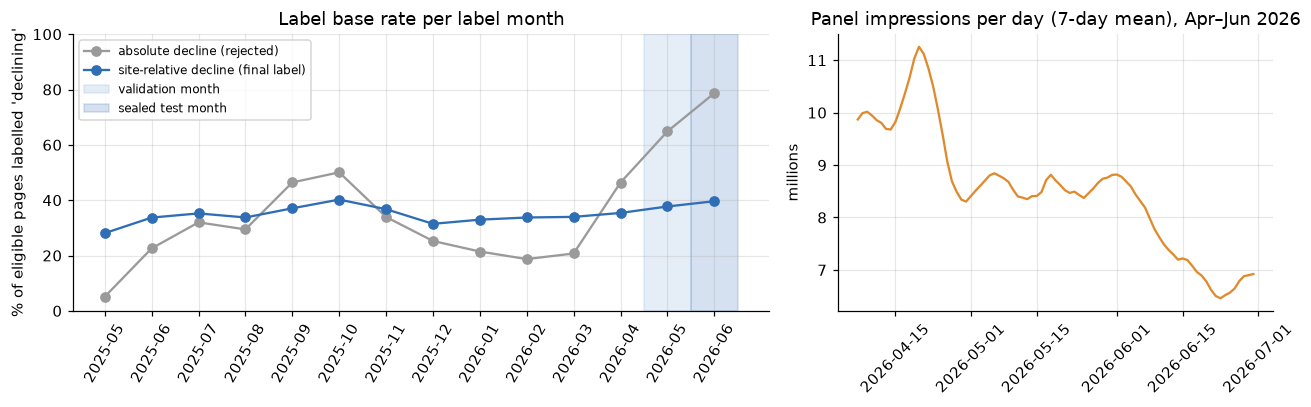

agreement absolute vs site-relative label (share of rows):
 y          0      1
y_abs              
0      0.473  0.069
1      0.167  0.291


,label_month,rows,clients,base_rate_absolute,base_rate_site_relative,drop_to_zero,median_ratio
0,2025-05,1410,1,0.051,0.281,0.000,1.576
1,2025-06,3880,2,0.226,0.337,0.008,1.311
2,2025-07,7609,3,0.320,0.352,0.011,1.099
3,2025-08,8912,4,0.294,0.338,0.013,1.096
4,2025-09,9193,5,0.464,0.371,0.005,0.852
5,2025-10,10173,8,0.501,0.402,0.005,0.799
6,2025-11,17811,10,0.339,0.367,0.004,1.065
7,2025-12,25218,13,0.253,0.315,0.003,1.193
8,2026-01,30583,13,0.214,0.330,0.004,1.395
9,2026-02,48520,17,0.187,0.337,0.003,1.531


In [7]:
P = panel
P["days_90"] = P.d1 + P.d2 + P.d3
P["imp_90"] = P.imp_f1 + P.imp_f2 + P.imp_f3
P["rate_90"] = P.imp_90 / P.days_90
P["is_live"] = P.label_month == "2026-07"
lab = ~P.is_live
P["label_ratio"] = np.where(lab, (P.imp_label / P.d_label) / P.rate_90, np.nan)  # analysis/label ONLY
P["drop_to_zero"] = lab & (P.imp_label == 0)

deleted_share = P.loc[lab, "is_deleted"].mean()
print(f"labelled rows whose page is deleted at export: {deleted_share:.2%} | drop-to-zero: "
      f"deleted {P.loc[lab & P.is_deleted, 'drop_to_zero'].mean():.1%} vs kept {P.loc[lab & ~P.is_deleted, 'drop_to_zero'].mean():.1%}")

# --- modelling population: pages not deleted at export ---
D = P[~P.is_deleted.fillna(False)].copy()
grp = D[~D.is_live].groupby(["client_hash_id", "label_month"]).label_ratio
D.loc[~D.is_live, "site_median_ratio"] = grp.transform("median")
D.loc[~D.is_live, "site_n"] = grp.transform("size")
D = D[D.is_live | (D.site_n >= 20)].reset_index(drop=True)
lab = ~D.is_live
D["y_abs"] = np.where(lab, (D.label_ratio < CONFIG["decline_ratio"]).astype(int), -1)
D["y"] = np.where(lab, (D.label_ratio < CONFIG["decline_ratio"] * D.site_median_ratio).astype(int), -1)

# daily totals Apr-Jun (one small remote query, cached): is June a data cut-off or a real slide?
DT = f"{CACHE}/daily_totals_apr_jun.parquet"
if not os.path.exists(DT):
    con.sql(f"""SELECT report_date, SUM(gsc_impressions) AS imp FROM read_parquet([
        {", ".join(f"'{REL}/fact_content_daily_performance/month={m}/*.parquet'" for m in ['2026-04','2026-05','2026-06'])}
        ]) GROUP BY 1 ORDER BY 1""").df().to_parquet(DT)
daily_tot = pd.read_parquet(DT)

by_month = (D[lab].groupby("label_month")
            .agg(rows=("y", "size"), clients=("client_hash_id", "nunique"),
                 base_rate_absolute=("y_abs", "mean"), base_rate_site_relative=("y", "mean"),
                 drop_to_zero=("drop_to_zero", "mean"), median_ratio=("label_ratio", "median"))
            .reset_index())
by_month.to_csv(f"{TAB}/label_base_rate_by_month.csv", index=False)
agree = pd.crosstab(D.loc[lab, "y_abs"], D.loc[lab, "y"], normalize=True)

RESULTS["label"] = {
    "definition": "page daily impressions in label month < 0.80 x site median ratio (eligible pages, same client, same month)",
    "deleted_share_of_labelled_rows": round(float(deleted_share), 4),
    "modelling_rows_labelled": int(lab.sum()), "live_rows": int(D.is_live.sum()),
    "base_rate_site_relative_overall": round(float(D.loc[lab, "y"].mean()), 4),
    "base_rate_absolute_overall": round(float(D.loc[lab, "y_abs"].mean()), 4),
    "test_month_base_rate_site_relative": round(float(D.loc[D.label_month == CONFIG["test_label_month"], "y"].mean()), 4),
    "test_month_base_rate_absolute": round(float(D.loc[D.label_month == CONFIG["test_label_month"], "y_abs"].mean()), 4),
    "daily_impressions_early_april": float(daily_tot.imp.head(7).mean()),
    "daily_impressions_late_june": float(daily_tot.imp.tail(7).mean()),
}
save_results()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
ax.plot(by_month.label_month, by_month.base_rate_absolute * 100, marker="o", color=COLORS["volume"], label="absolute decline (rejected)")
ax.plot(by_month.label_month, by_month.base_rate_site_relative * 100, marker="o", color=COLORS["model"], label="site-relative decline (final label)")
ax.axvspan(len(by_month) - 2.5, len(by_month) - 1.5, color="#7FA7D9", alpha=0.2, label="validation month")
ax.axvspan(len(by_month) - 1.5, len(by_month) - 0.5, color="#2F6DB5", alpha=0.2, label="sealed test month")
ax.set_ylim(0, 100); ax.set_ylabel("% of eligible pages labelled 'declining'")
ax.set_title("Label base rate per label month"); ax.tick_params(axis="x", rotation=60); ax.legend(fontsize=8, loc="upper left")
ax = axes[1]
ax.plot(daily_tot.report_date, daily_tot.imp.rolling(7).mean() / 1e6, color=COLORS["momentum"])
ax.set_title("Panel impressions per day (7-day mean), Apr–Jun 2026"); ax.set_ylabel("millions"); ax.tick_params(axis="x", rotation=45)
fig.tight_layout(); fig.savefig(f"{FIG}/fig01_label_base_rate.png", bbox_inches="tight"); plt.show()

print("agreement absolute vs site-relative label (share of rows):\n", agree.round(3))
by_month.round(3)

**Reading the label.** The site-relative label is stable at **31–40%** in every month with more than one client, while the absolute label swings from 19% to 79% with site-wide shocks. The two labels agree on 76% of rows; they disagree mostly on pages that fell *with* their site (absolute = 1, relative = 0: 16.7% of rows) — exactly the cases a page-level refresh cannot fix. Only 0.12% of labelled rows belonged to pages deleted at export (18.5% of those dropped to zero, vs. 0.7% for kept pages), so the deletion exclusion is small but removes obvious "removal, not decay" positives. In the sealed test month the site-relative base rate is **39.6%** — this is the number every precision figure must be compared against.

### 3.2 Features (all computed from the feature window, i.e. on or before decision date *T*)

| Group | Features | Why |
|---|---|---|
| Visibility level | `log_imp_90`, `log_clk_90` | scale of exposure |
| Momentum | `mom_f3_vs_90` (last month ÷ 3-month avg), `mom_f2_vs_f1`, `mom_f3_vs_f2`, `mom_h2_vs_f3` (2nd half of last month ÷ whole last month), `cv_3m` | is the page already sliding, and how noisy is it? |
| Position & CTR | `pos_90`, `pos_delta` (last − first month; + = worse), `ctr_90`, `ctr_delta` | SERP standing and click capture |
| Persistence | `active_share_f3`, `active_share_90` | share of days with ≥ 1 impression |
| Engagement (GA4, only rows with `ga4_data_available IS TRUE`) | `has_ga4`, `ses_per_day`, `engaged_rate`, `organic_share`, `has_ai_sessions` | engagement context; missing ⇒ NaN + flag, never 0 |
| Site context | `site_mom_f3_vs_90`, `site_mom_f3_vs_f1`, `rel_mom_vs_site`, `log_site_pages` | separates site-wide movement from page-specific movement |
| Page / keyword metadata | `age_days`, `content_type`, `main_intent`, `competition_level`, `word_count`, `search_volume`, `cpc`, `competition`, `backlinks`, `keyword_token_count`, `category_count` (+ `has_kw_data` flag) | page and target-keyword context |

**Excluded on purpose:** `content_hash_id` / `client_hash_id` (pseudonyms: grouping only), `content_updated_date`, `last_optimized_date`, `optimization_eligible_date` (latest value at export; for 15% of keyword articles the update date is *after* the panel ends ⇒ future information), `is_deleted` / `is_published` (export-time status), `provider_used` / `model_used` (generation metadata, not a signal), everything from `fact_content_query_90d` (window overlaps the test month), and anything computed from the label month. `dim_content` metadata is a snapshot at export time; an ablation in §4 shows whether the results depend on it.

In [8]:
def safe_div(a, b):
    a = np.asarray(a, dtype="float64"); b = np.asarray(b, dtype="float64")
    return np.divide(a, b, out=np.full_like(a, np.nan), where=b > 0)

r1, r2, r3 = D.imp_f1 / D.d1, D.imp_f2 / D.d2, D.imp_f3 / D.d3
rates = np.vstack([r1, r2, r3]).T
F = pd.DataFrame(index=D.index)
F["log_imp_90"]      = np.log1p(D.imp_90)
F["log_clk_90"]      = np.log1p(D.clk_f1 + D.clk_f2 + D.clk_f3)
F["mom_f3_vs_90"]    = safe_div(r3, D.rate_90)
F["mom_f2_vs_f1"]    = safe_div(r2, r1)
F["mom_f3_vs_f2"]    = safe_div(r3, r2)
F["mom_h2_vs_f3"]    = safe_div(D.imp_h2_f3 / (D.d3 - 15), r3)
F["cv_3m"]           = rates.std(axis=1) / rates.mean(axis=1)
F["pos_90"]          = safe_div(D.sp_90, D.imp_90)
F["pos_delta"]       = safe_div(D.sp_f3, D.imp_f3) - safe_div(D.sp_f1, D.imp_f1)
F["ctr_90"]          = safe_div(D.clk_f1 + D.clk_f2 + D.clk_f3, D.imp_90)
F["ctr_delta"]       = safe_div(D.clk_f3, D.imp_f3) - safe_div(D.clk_f1, D.imp_f1)
F["active_share_f3"] = D.act_f3 / D.d3
F["active_share_90"] = D.act_90 / D.days_90
F["has_ga4"]         = (D.ga4_days.fillna(0) > 0).astype(int)
F["ses_per_day"]     = np.where(F.has_ga4 == 1, safe_div(D.sessions, D.ga4_days), np.nan)
F["engaged_rate"]    = safe_div(D.engaged, D.sessions)
F["organic_share"]   = safe_div(D.ses_org, D.sessions)
F["has_ai_sessions"] = (D.ses_ai.fillna(0) > 0).astype(int)
F["site_mom_f3_vs_90"] = safe_div(D.c_rate_f3, D.c_rate_90)
F["site_mom_f3_vs_f1"] = safe_div(D.c_rate_f3, D.c_rate_f1)
F["rel_mom_vs_site"]   = F.mom_f3_vs_90 / F.site_mom_f3_vs_90
F["log_site_pages"]    = np.log1p(D.c_pages_f3)
F["age_days"]        = D.age_days
for c in ["word_count", "search_volume", "cpc", "competition", "backlinks", "keyword_token_count", "category_count"]:
    F[c] = D[c].astype("float64")
F["has_kw_data"]     = D.search_volume.notna().astype(int)
CAT = ["content_type", "main_intent", "competition_level"]
for c in CAT:
    F[c] = D[c].fillna("missing").astype("category")

NUM = [c for c in F.columns if c not in CAT]
META = ["age_days", "word_count", "search_volume", "cpc", "competition", "backlinks",
        "keyword_token_count", "category_count", "has_kw_data"] + CAT
FEATURES = NUM + CAT
print(f"{len(FEATURES)} features ({len(NUM)} numeric, {len(CAT)} categorical)")

# missingness by content_type (systematic, not random -> NaN + flags, no blind fillna(0))
miss = F[["word_count", "search_volume", "backlinks", "ses_per_day", "pos_delta"]].isna().groupby(D.content_type).mean()
miss["rows"] = D.content_type.value_counts()
miss.round(3).to_csv(f"{TAB}/missingness_by_content_type.csv")
RESULTS["features"] = {"numeric": NUM, "categorical": CAT, "metadata_block": META}
save_results()
display(miss.round(3))
F.describe().T[["mean", "50%", "min", "max"]].round(3)

34 features (31 numeric, 3 categorical)


,word_count,search_volume,backlinks,ses_per_day,pos_delta,rows
content_type,,,,,,
comparison article,0.000,0.000,0.005,0.107,0.0,1795
feedly article,0.000,1.000,1.000,0.459,0.0,4887
keyword article,0.376,0.015,0.538,0.507,0.0,526778


,mean,50%,min,max
log_imp_90,7.820,7.657,5.707,14.515
log_clk_90,1.812,1.609,0.000,9.757
mom_f3_vs_90,0.992,0.968,0.000,3.212
mom_f2_vs_f1,3.347,1.094,0.000,7620.516
mom_f3_vs_f2,1.624,0.942,0.000,5460.133
mom_h2_vs_f3,0.963,0.985,0.000,2.154
cv_3m,0.389,0.340,0.001,1.413
pos_90,15.249,9.109,0.015,183.843
pos_delta,2.440,1.116,-290.029,571.137
ctr_90,0.003,0.002,0.000,0.198


**Reading the features.** Missingness is systematic, exactly as the data dictionary warns: feedly articles have **no** keyword data (`search_volume`, `backlinks` 100% missing), keyword articles miss `word_count` 38% of the time, and about half the rows have no GA4 coverage. These stay `NaN` with explicit flags (`has_kw_data`, `has_ga4`) — a blind `fillna(0)` would inject a content-type signal and call "no tracking" zero engagement. Ratio features have heavy tails (e.g. `mom_f2_vs_f1` up to 7,620 for pages that went from almost nothing to visible); tree models are insensitive to this, and the linear model gets a quantile transform inside its pipeline.

### 3.3 Split design, baselines and leakage checks

**Time-aware split (train on the past, test on the future):**

| Role | Label months | Decision dates | Used for |
|---|---|---|---|
| train (selection) | 2025-05 … 2026-04 | ≤ 2026-03-31 | fit candidates |
| validation | 2026-05 | 2026-04-30 | pick model + hyper-parameters |
| train (final) | 2025-05 … 2026-05 | ≤ 2026-04-30 | refit chosen model once |
| **sealed test** | **2026-06** | 2026-05-31 | **evaluated once** |
| live queue | 2026-07 (no outcome yet) | 2026-06-30 | the recommendations |

The same page can appear at several decision dates. That is the real deployment situation (FlyRank knows its pages' history), but it lets a model partly "remember" pages and clients. A second, stricter check — **unseen clients + future month** (5-fold grouped by client on top of the time split) — measures how much of the result survives on sites the model never saw.

**Baselines** (transparent rules, scored on exactly the same rows):
- **B0 — volume rule (my w04 baseline):** flag pages ≥ 90 days old with ≥ 500 impressions last month; rank by log impressions.
- **B1 — momentum rule:** rank by how far last month fell below the page's 3-month average (`1 − mom_f3_vs_90`).
- **B2 — site-relative momentum rule:** rank by how far the page's momentum lags its own site's (`1 − rel_mom_vs_site`). This is the strongest simple rule I could write and the real bar the model has to clear.

**Leakage checks** (code below): forbidden columns are absent from the feature list; every feature month precedes its label month; no single feature is suspiciously predictive on its own; and a model trained on **shuffled labels** scores at chance.

In [9]:
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.ensemble import HistGradientBoostingClassifier

FORBIDDEN = {"y", "y_abs", "label_ratio", "imp_label", "clk_label", "site_median_ratio", "site_n", "drop_to_zero",
             "is_deleted", "is_published", "content_hash_id", "client_hash_id", "content_updated_date",
             "last_optimized_date", "optimization_eligible_date", "provider_used", "model_used", "rate_label"}
assert not FORBIDDEN & set(FEATURES), FORBIDDEN & set(FEATURES)

# every feature month strictly precedes its label month (by construction of panel_sql)
win = pd.DataFrame([{"label_month": L, "feature_months": f"{MONTHS[mi_of[L]-3]}..{MONTHS[mi_of[L]-1]}",
                     "decision_date": str(pd.Period(MONTHS[mi_of[L]-1]).end_time.date())}
                    for L in LABEL_MONTHS[-4:]] +
                   [{"label_month": "2026-07 (live)", "feature_months": "2026-04..2026-06", "decision_date": "2026-06-30"}])
assert (pd.to_datetime(D.decision_date) < pd.to_datetime(D.label_month + "-01")).all()

y = D.y.values
m_tr = (D.label_month <= "2026-04").values
m_va = (D.label_month == CONFIG["val_label_month"]).values
m_trf = (D.label_month <= CONFIG["val_label_month"]).values
m_te = (D.label_month == CONFIG["test_label_month"]).values
m_live = D.is_live.values
assert not (m_trf & m_te).any() and not (m_tr & m_va).any()

# single-feature AUC probe on the TRAINING rows only (|AUC-0.5| > 0.4 would be suspicious)
probe = []
for c in NUM:
    v = F.loc[m_tr, c]
    ok = v.notna().values
    if ok.sum() > 1000:
        a = roc_auc_score(y[m_tr][ok], v.values[ok])
        probe.append({"feature": c, "auc_alone": round(max(a, 1 - a), 3), "direction": "+" if a >= 0.5 else "-",
                      "coverage": round(ok.mean(), 3)})
probe = pd.DataFrame(probe).sort_values("auc_alone", ascending=False)
assert probe.auc_alone.max() < 0.9, "a single feature nearly encodes the label -> investigate"

# shuffled-label test: same model, permuted training labels -> validation AUC must centre on 0.5.
# One run can drift (an arbitrary function of strong features correlates with y by chance), so use 6 seeds.
shuf_aucs = []
for s in range(6):
    shuf = HistGradientBoostingClassifier(max_iter=100, random_state=s, categorical_features="from_dtype",
                                          early_stopping=False)
    shuf.fit(F.loc[m_tr, FEATURES], np.random.default_rng(s).permutation(y[m_tr]))
    shuf_aucs.append(roc_auc_score(y[m_va], shuf.predict_proba(F.loc[m_va, FEATURES])[:, 1]))
auc_shuf = float(np.mean(shuf_aucs))
print(f"shuffled-label models, validation ROC-AUC: mean {auc_shuf:.3f} "
      f"(range {min(shuf_aucs):.3f}-{max(shuf_aucs):.3f}; chance = 0.5)")
assert abs(auc_shuf - 0.5) < 0.03

print(f"rows -> train(sel) {m_tr.sum():,} | val {m_va.sum():,} | train(final) {m_trf.sum():,} | "
      f"test {m_te.sum():,} | live {m_live.sum():,}")
RESULTS["leakage_checks"] = {"forbidden_columns_absent": True, "feature_months_precede_label": True,
                             "max_single_feature_auc": float(probe.auc_alone.max()),
                             "top_single_feature": probe.iloc[0].feature,
                             "shuffled_label_val_auc_mean": round(auc_shuf, 4),
                             "shuffled_label_val_auc_range": [round(min(shuf_aucs), 4), round(max(shuf_aucs), 4)]}
RESULTS["split_rows"] = {"train_selection": int(m_tr.sum()), "validation": int(m_va.sum()),
                         "train_final": int(m_trf.sum()), "test": int(m_te.sum()), "live": int(m_live.sum())}
save_results()
probe.to_csv(f"{TAB}/single_feature_auc_probe.csv", index=False)
display(win)
probe.head(12)

shuffled-label models, validation ROC-AUC: mean 0.500 (range 0.454-0.549; chance = 0.5)
rows -> train(sel) 275,266 | val 76,025 | train(final) 351,291 | test 89,237 | live 92,932


,label_month,feature_months,decision_date
0,2026-03,2025-12..2026-02,2026-02-28
1,2026-04,2026-01..2026-03,2026-03-31
2,2026-05,2026-02..2026-04,2026-04-30
3,2026-06,2026-03..2026-05,2026-05-31
4,2026-07 (live),2026-04..2026-06,2026-06-30


,feature,auc_alone,direction,coverage
20,rel_mom_vs_site,0.749,-,1.000
2,mom_f3_vs_90,0.733,-,1.000
4,mom_f3_vs_f2,0.715,-,1.000
5,mom_h2_vs_f3,0.665,-,1.000
9,ctr_90,0.590,-,1.000
3,mom_f2_vs_f1,0.586,-,1.000
11,active_share_f3,0.575,-,1.000
1,log_clk_90,0.551,-,1.000
12,active_share_90,0.534,-,1.000
25,cpc,0.519,+,0.968


**Reading the checks.** All four leakage checks pass. The strongest single feature, `rel_mom_vs_site` (ROC-AUC 0.75 alone), is a *momentum* signal from the feature window: pages already lagging their site tend to keep lagging. That is a plausible, non-leaky pattern — and it means baseline B2 will be hard to beat. Shuffled-label models centre on chance (mean 0.500; single runs range 0.45–0.55, which is why one run is not enough). The split sizes are 275k training rows for selection, 76k validation rows, 351k rows for the final fit and 89k sealed test rows.

## 4. Results (vs baseline)

### 4.1 Model selection on the validation month (May 2026)
Candidates, each a scikit-learn `Pipeline` fitted on training months only (no transform ever sees validation or test rows):
- **Logistic regression** — median imputation with missing-indicators → quantile-normal transform → L2 logistic regression (+ one-hot categories);
- **Histogram gradient boosting (HGB)** — native NaN handling and native categorical splits; a small grid over learning rate / leaf count / L2.

The selection metric is **average precision (PR-AUC)** on the validation month; Precision@K and ROC-AUC are reported alongside. The test month is not touched here.

In [10]:
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer, OneHotEncoder
from sklearn.linear_model import LogisticRegression

def precision_at_k(y_true, score, k):
    order = np.lexsort((np.arange(len(score)), -np.asarray(score)))[:k]   # stable: ties keep row order
    return float(np.asarray(y_true)[order].mean())

# impressions the page lost relative to what its site's typical page kept (label-month info: evaluation only)
D["imp_lost_vs_site"] = np.where(~D.is_live, np.maximum(0, D.rate_90 * D.d_label * D.site_median_ratio - D.imp_label), np.nan)

def evaluate(mask, score, name):
    y_true = y[mask]; score = np.asarray(score, dtype=float); base = y_true.mean()
    row = {"model": name, "PR-AUC": average_precision_score(y_true, score),
           "ROC-AUC": roc_auc_score(y_true, score), "base_rate": base}
    for k in CONFIG["top_k"]:
        row[f"P@{k}"] = precision_at_k(y_true, score, k)
    k10 = int(0.10 * len(y_true))
    top10 = np.lexsort((np.arange(len(score)), -score))[:k10]
    row["P@top10%"] = float(y_true[top10].mean())
    row["lift@top10%"] = row["P@top10%"] / base
    lost = D.loc[mask, "imp_lost_vs_site"].values
    row["lost_imp_captured@top10%"] = float(lost[top10].sum() / lost.sum())
    # each site's editor gets their own top-20: mean precision over sites with >= 100 eligible pages
    g = pd.DataFrame({"c": D.loc[mask, "client_hash_id"].values, "y": y_true, "s": score})
    per = [precision_at_k(d.y.values, d.s.values, 20) for _, d in g.groupby("c") if len(d) >= 100]
    row["site_P@20_mean"] = float(np.mean(per))
    return row

def baseline_scores(idx):
    f = F.loc[idx]
    imp_last = D.loc[idx, "imp_f3"]
    return {
        "B0 volume rule (w04)": np.where((f.age_days >= 90) & (imp_last >= 500), np.log10(1 + imp_last), 0.0),
        "B1 momentum rule": 1 - f.mom_f3_vs_90.values,
        "B2 site-relative momentum rule": 1 - f.rel_mom_vs_site.values,
    }

def make_logit():
    pre = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                              QuantileTransformer(output_distribution="normal", n_quantiles=200,
                                                  subsample=200_000, random_state=SEED)), NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CAT)])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(C=0.5, max_iter=2000))])

def make_hgb(lr=0.05, leaves=31, l2=1.0, iters=400):
    return HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=leaves, l2_regularization=l2,
                                          max_iter=iters, min_samples_leaf=100, early_stopping=False,
                                          categorical_features="from_dtype", random_state=SEED)

candidates = {"logistic regression": make_logit()}
for lr, leaves, l2, iters in [(0.05, 31, 1.0, 300), (0.05, 63, 1.0, 400), (0.03, 63, 5.0, 600), (0.1, 15, 1.0, 200)]:
    candidates[f"HGB lr={lr} leaves={leaves} l2={l2} iters={iters}"] = make_hgb(lr, leaves, l2, iters)

Xtr, Xva = F.loc[m_tr, FEATURES], F.loc[m_va, FEATURES]
val_rows, val_scores = [], {}
for name, est in candidates.items():
    t = time.time(); est.fit(Xtr, y[m_tr])
    val_scores[name] = est.predict_proba(Xva)[:, 1]
    val_rows.append(evaluate(m_va, val_scores[name], name) | {"fit_s": round(time.time() - t, 1)})
for name, s in baseline_scores(m_va).items():
    val_rows.append(evaluate(m_va, s, name))
val_tab = pd.DataFrame(val_rows).sort_values("PR-AUC", ascending=False)

best_name = val_tab[val_tab.model.str.startswith("HGB") | (val_tab.model == "logistic regression")].iloc[0].model
print("selected on validation PR-AUC ->", best_name)
val_tab.to_csv(f"{TAB}/validation_model_selection.csv", index=False)
RESULTS["model_selection"] = {"selected": best_name, "validation_month": CONFIG["val_label_month"],
                              "validation_table": val_tab.round(4).to_dict(orient="records")}
save_results()
val_tab.drop(columns=["P@20", "P@50"]).round(3)

selected on validation PR-AUC -> HGB lr=0.05 leaves=31 l2=1.0 iters=300


,model,PR-AUC,ROC-AUC,base_rate,P@100,P@500,P@top10%,lift@top10%,lost_imp_captured@top10%,site_P@20_mean,fit_s
1,HGB lr=0.05 leaves=31 l2=1.0 iters=300,0.734,0.797,0.377,0.99,0.982,0.881,2.336,0.280,0.940,8.7
3,HGB lr=0.03 leaves=63 l2=5.0 iters=600,0.733,0.792,0.377,1.00,0.982,0.886,2.347,0.323,0.925,20.0
4,HGB lr=0.1 leaves=15 l2=1.0 iters=200,0.731,0.794,0.377,0.99,0.966,0.872,2.310,0.282,0.918,4.8
2,HGB lr=0.05 leaves=63 l2=1.0 iters=400,0.729,0.793,0.377,1.00,0.984,0.880,2.332,0.315,0.928,13.0
0,logistic regression,0.709,0.788,0.377,0.97,0.956,0.843,2.235,0.215,0.945,40.8
7,B2 site-relative momentum rule,0.673,0.748,0.377,0.98,0.956,0.818,2.169,0.156,0.930,NaN
6,B1 momentum rule,0.650,0.723,0.377,0.98,0.956,0.801,2.122,0.136,0.930,NaN
5,B0 volume rule (w04),0.331,0.407,0.377,0.08,0.120,0.255,0.677,0.396,0.118,NaN


**Reading the validation table.**
- All four HGB settings land within 0.005 PR-AUC of each other, so the choice is not fragile; the simplest one (lr 0.05, 31 leaves, 300 iterations) is kept. HGB beats logistic regression (0.734 vs 0.709 PR-AUC), so the non-linear model earns its complexity — but only modestly.
- The real bar is **B2**, the site-relative momentum rule: 0.673 PR-AUC. HGB adds +0.06 PR-AUC and +0.05 ROC-AUC on top of it, and catches more of the lost impressions in its top 10% (28% vs 16%).
- Precision at small K (P@20…P@500) is ~0.96–1.00 for **every** sensible ranker including the rules: the very top of any momentum-aware list is pages that are already collapsing, and they keep falling. Small-K precision cannot separate the methods here, so the paper leads with PR-AUC, precision in the top 10% and per-site precision.
- **Negative result:** my w04 volume rule ranks *worse than chance* (ROC-AUC 0.41): high-volume pages are *less* likely to fall behind their own site. Yet it catches 40% of lost impressions in its top 10%, simply because big pages lose big absolute numbers. Probability of decline and size of the loss are different questions — the action queue in §6 uses both.

### 4.2 Sealed test month (June 2026) — evaluated once
The selected configuration is refit on all label months ≤ May 2026 and scored on June 2026, together with the three baselines, on exactly the same 89k rows. Two rankings come out of the model:
- **model — probability**: rank by P(decline) → "which pages are most likely to fall behind?"
- **model — expected impact**: rank by P(decline) × current daily impressions → "where is the most visibility at stake?"

Uncertainty: a **cluster bootstrap over clients** (300 resamples of whole sites) gives 95% intervals for the PR-AUC gap between the model and B2, because pages of the same site are not independent.

In [11]:
final_model = candidates[best_name]
from sklearn.base import clone
final_model = clone(final_model).fit(F.loc[m_trf, FEATURES], y[m_trf])

p_test = final_model.predict_proba(F.loc[m_te, FEATURES])[:, 1]
impact_test = p_test * D.loc[m_te, "rate_90"].values
test_scores = {"model — probability": p_test, "model — expected impact": impact_test} | baseline_scores(m_te)
test_tab = pd.DataFrame([evaluate(m_te, s, n) for n, s in test_scores.items()])

# secondary outcome: the same scores against the ABSOLUTE decline label
for n, s in test_scores.items():
    ya = D.loc[m_te, "y_abs"].values
    test_tab.loc[test_tab.model == n, "ROC-AUC (absolute label)"] = roc_auc_score(ya, s)

# cluster bootstrap over clients for the PR-AUC gap model vs B2
cl = D.loc[m_te, "client_hash_id"].values
yt = y[m_te]; sB2 = test_scores["B2 site-relative momentum rule"]
uc = np.unique(cl); idx_by_c = {c: np.where(cl == c)[0] for c in uc}
rng = np.random.default_rng(SEED); gaps, roc_gaps = [], []
for _ in range(300):
    ii = np.concatenate([idx_by_c[c] for c in rng.choice(uc, len(uc), replace=True)])
    if yt[ii].min() == yt[ii].max():
        continue
    gaps.append(average_precision_score(yt[ii], p_test[ii]) - average_precision_score(yt[ii], sB2[ii]))
    roc_gaps.append(roc_auc_score(yt[ii], p_test[ii]) - roc_auc_score(yt[ii], sB2[ii]))
ci = np.round(np.percentile(gaps, [2.5, 97.5]), 4); ci_roc = np.round(np.percentile(roc_gaps, [2.5, 97.5]), 4)
print(f"PR-AUC gap model - B2: {np.mean(gaps):+.3f} (95% cluster-bootstrap CI {ci[0]:+.3f} .. {ci[1]:+.3f}); "
      f"share of resamples with gap > 0: {np.mean(np.array(gaps) > 0):.0%}")
print(f"ROC-AUC gap model - B2: {np.mean(roc_gaps):+.3f} (95% CI {ci_roc[0]:+.3f} .. {ci_roc[1]:+.3f})")

test_tab.to_csv(f"{TAB}/test_results.csv", index=False)
RESULTS["test"] = {"label_month": CONFIG["test_label_month"], "rows": int(m_te.sum()),
                   "base_rate": round(float(yt.mean()), 4),
                   "table": test_tab.round(4).to_dict(orient="records"),
                   "prauc_gap_vs_B2": {"mean": round(float(np.mean(gaps)), 4), "ci95": [round(float(c), 4) for c in ci],
                                        "share_positive": round(float(np.mean(np.array(gaps) > 0)), 3)},
                   "rocauc_gap_vs_B2": {"mean": round(float(np.mean(roc_gaps)), 4), "ci95": [round(float(c), 4) for c in ci_roc]},
                   "evaluated_once": True}
save_results()
test_tab.drop(columns=["P@20", "P@50"]).round(3)

PR-AUC gap model - B2: +0.041 (95% cluster-bootstrap CI +0.021 .. +0.067); share of resamples with gap > 0: 100%
ROC-AUC gap model - B2: +0.046 (95% CI +0.034 .. +0.063)


,model,PR-AUC,ROC-AUC,base_rate,P@100,P@500,P@top10%,lift@top10%,lost_imp_captured@top10%,site_P@20_mean,ROC-AUC (absolute label)
0,model — probability,0.724,0.800,0.396,0.91,0.914,0.857,2.163,0.329,0.889,0.751
1,model — expected impact,0.497,0.614,0.396,0.55,0.576,0.573,1.447,0.656,0.552,0.629
2,B0 volume rule (w04),0.343,0.379,0.396,0.11,0.086,0.208,0.526,0.380,0.104,0.410
3,B1 momentum rule,0.666,0.743,0.396,0.93,0.954,0.806,2.034,0.149,0.896,0.764
4,B2 site-relative momentum rule,0.683,0.755,0.396,0.92,0.954,0.822,2.076,0.174,0.896,0.734


**Reading the sealed test.** On June 2026 (base rate 39.6%), the model's probability ranking reaches **PR-AUC 0.724 / ROC-AUC 0.800**, against 0.683 / 0.755 for the best rule (B2). The gap is modest but consistent: **+0.041 PR-AUC, 95% cluster-bootstrap CI +0.021 … +0.067**, positive in 100% of the 300 site-level resamples. Within the top 10% of the queue, 86% of pages really fell behind their site (lift 2.2× over the base rate) vs 82% for B2. Small-K precision is again high for every momentum-aware ranker (P@100 0.91–0.93), so it does not separate them.

The **expected-impact ranking** answers a different question and wins it clearly: its top 10% holds **66% of all impressions lost relative to site trend**, vs 38% for the volume rule and 17% for B2 — at the cost of lower precision (57%), because large pages that lose a lot are rarer than small pages that lose a little. Neither ranking is "better"; they are two lenses, and the playbook (§6) uses both.

Secondary outcome: against the *absolute* decline label the model is not better than the momentum rules (ROC-AUC 0.75 vs 0.73–0.76) — expected, since it was trained to separate page-specific from site-wide movement, not to forecast site-wide shocks.

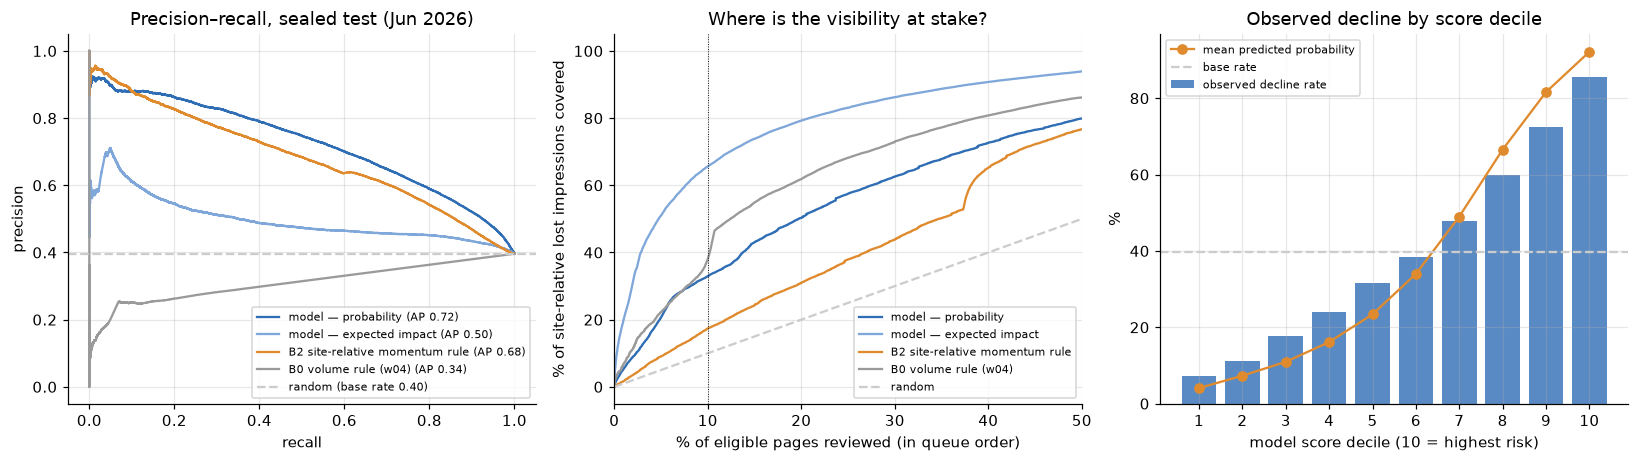

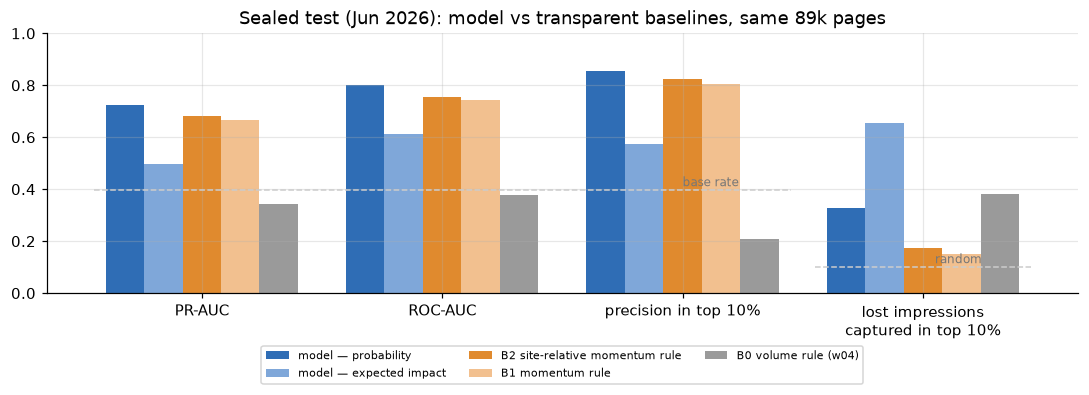

In [12]:
from sklearn.metrics import precision_recall_curve
plot_set = {"model — probability": COLORS["model"], "model — expected impact": COLORS["logit"],
            "B2 site-relative momentum rule": COLORS["momentum"], "B0 volume rule (w04)": COLORS["volume"]}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
ax = axes[0]
for n, c in plot_set.items():
    pr, rc, _ = precision_recall_curve(yt, test_scores[n])
    ax.plot(rc, pr, color=c, label=f"{n} (AP {average_precision_score(yt, test_scores[n]):.2f})")
ax.axhline(yt.mean(), color=COLORS["random"], ls="--", label=f"random (base rate {yt.mean():.2f})")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title("Precision–recall, sealed test (Jun 2026)")
ax.legend(fontsize=7.5)

ax = axes[1]
lost = D.loc[m_te, "imp_lost_vs_site"].values
share = np.arange(1, len(yt) + 1) / len(yt)
for n, c in plot_set.items():
    o = np.lexsort((np.arange(len(yt)), -np.asarray(test_scores[n], float)))
    ax.plot(share * 100, np.cumsum(lost[o]) / lost.sum() * 100, color=c, label=n)
ax.plot([0, 100], [0, 100], color=COLORS["random"], ls="--", label="random")
ax.axvline(10, color="k", lw=0.6, ls=":")
ax.set_xlim(0, 50); ax.set_xlabel("% of eligible pages reviewed (in queue order)")
ax.set_ylabel("% of site-relative lost impressions covered"); ax.set_title("Where is the visibility at stake?")
ax.legend(fontsize=7.5)

ax = axes[2]
dec = pd.DataFrame({"y": yt, "p": p_test})
dec["decile"] = pd.qcut(dec.p.rank(method="first"), 10, labels=False) + 1
cal = dec.groupby("decile").agg(pred=("p", "mean"), obs=("y", "mean"))
ax.bar(cal.index, cal.obs * 100, color=COLORS["model"], alpha=0.8, label="observed decline rate")
ax.plot(cal.index, cal.pred * 100, "o-", color=COLORS["momentum"], label="mean predicted probability")
ax.axhline(yt.mean() * 100, color=COLORS["random"], ls="--", label="base rate")
ax.set_xlabel("model score decile (10 = highest risk)"); ax.set_ylabel("%"); ax.set_xticks(range(1, 11))
ax.set_title("Observed decline by score decile"); ax.legend(fontsize=7.5)
fig.tight_layout(); fig.savefig(f"{FIG}/fig02_test_ranking_quality.png", bbox_inches="tight"); plt.show()

# compact bar chart: model vs baselines on the headline metrics
mets = ["PR-AUC", "ROC-AUC", "P@top10%", "lost_imp_captured@top10%"]
order = ["model — probability", "model — expected impact", "B2 site-relative momentum rule", "B1 momentum rule", "B0 volume rule (w04)"]
tt = test_tab.set_index("model").loc[order, mets]
fig, ax = plt.subplots(figsize=(10, 3.8))
w = 0.16
cols = [COLORS["model"], COLORS["logit"], COLORS["momentum"], "#F2C08F", COLORS["volume"]]
for i, (n, c) in enumerate(zip(order, cols)):
    ax.bar(np.arange(len(mets)) + (i - 2) * w, tt.loc[n], w, color=c, label=n)
ax.hlines(yt.mean(), -0.45, 2.45, color=COLORS["random"], ls="--", lw=1)   # base rate: precision metrics
ax.text(2.0, yt.mean() + 0.015, "base rate", fontsize=8, color="#777")
ax.hlines(0.10, 2.55, 3.45, color=COLORS["random"], ls="--", lw=1)          # random reviewer covers 10%
ax.text(3.05, 0.115, "random", fontsize=8, color="#777")
ax.set_xticks(range(len(mets))); ax.set_xticklabels(["PR-AUC", "ROC-AUC", "precision in top 10%", "lost impressions\ncaptured in top 10%"])
ax.set_ylim(0, 1); ax.set_title("Sealed test (Jun 2026): model vs transparent baselines, same 89k pages")
ax.legend(fontsize=7.5, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
fig.tight_layout(); fig.savefig(f"{FIG}/fig03_test_metrics_bar.png", bbox_inches="tight"); plt.show()
cal.round(3).to_csv(f"{TAB}/test_decile_calibration.csv")
RESULTS["test"]["decile_observed_rate"] = cal.obs.round(4).tolist()
save_results()

**Reading the charts.** The precision–recall curve of the model sits above B2 across almost the whole recall range — the gain is not concentrated at one threshold. The coverage curve shows the impact ranking reaching ~65% of the lost impressions after reviewing 10% of pages and ~80% after 20%. The decile chart shows a clean monotone ranking (7.2% observed decline in the lowest decile → 86% in the highest); the probabilities are **not perfectly calibrated** for June — the model under-predicts in the middle deciles and over-predicts at the top, because June's base rate (39.6%) is higher than the training months' (~34%). Treat scores as a **ranking**, not as literal probabilities.

### 4.3 Robustness: unseen sites, what drives the score, and what breaks it
1. **Unseen clients + future month.** 5-fold `GroupKFold` over clients: for each fold, train on label months ≤ May 2026 of the *other* clients, score June for the held-out clients. If the score holds, the model is not just memorising sites.
2. **Permutation importance** on the sealed test month (drop in PR-AUC when a feature is shuffled), for the probability ranking.
3. **Ablation:** drop the export-time `dim_content` metadata block (keeps only behaviour observed before *T*).
4. **Sensitivity:** decline threshold 0.7 / 0.8 / 0.9 × site median. (Pages deleted at export are only 0.12% of labelled rows — §3.1 — so re-including them cannot move these metrics materially; that check is not repeated here.)

                                       model  PR-AUC  ROC-AUC  P@top10%  lift@top10%  site_P@20_mean
                         model — probability   0.724    0.800     0.857        2.163           0.889
         model — probability, unseen clients   0.695    0.769     0.830        2.094           0.896
              B2 site-relative momentum rule   0.683    0.755     0.822        2.076           0.896
model — probability, no dim_content metadata   0.717    0.790     0.849        2.142           0.887


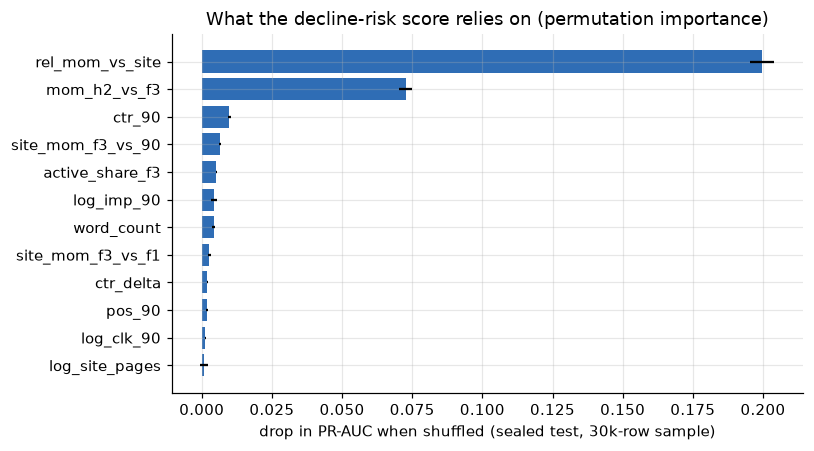

,feature,importance,std
20,rel_mom_vs_site,0.1997,0.0043
5,mom_h2_vs_f3,0.0727,0.0023
9,ctr_90,0.0099,0.0006
18,site_mom_f3_vs_90,0.0066,0.0003
11,active_share_f3,0.0052,0.0002
0,log_imp_90,0.0044,0.0010
23,word_count,0.0042,0.0004
19,site_mom_f3_vs_f1,0.0027,0.0006
10,ctr_delta,0.0020,0.0001
7,pos_90,0.0019,0.0003


In [13]:
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance

# 1) unseen clients + future month
groups = D.client_hash_id.values
te_idx = np.where(m_te)[0]
p_ho = np.full(len(te_idx), np.nan)
for k, (_, ho) in enumerate(GroupKFold(n_splits=5).split(te_idx, groups=groups[te_idx])):
    ho_clients = set(groups[te_idx[ho]])
    tr_mask = m_trf & ~np.isin(groups, list(ho_clients))
    mdl = clone(candidates[best_name]).fit(F.loc[tr_mask, FEATURES], y[tr_mask])
    p_ho[ho] = mdl.predict_proba(F.loc[te_idx[ho], FEATURES])[:, 1]
ho_row = evaluate(m_te, p_ho, "model — probability, unseen clients")
rob = pd.DataFrame([test_tab.iloc[0].to_dict(), ho_row, test_tab.set_index("model").loc["B2 site-relative momentum rule"].to_dict() | {"model": "B2 site-relative momentum rule"}])

# 3) ablation: no export-time metadata
FEAT_NOMETA = [c for c in FEATURES if c not in META]
mdl_nm = make_hgb(0.05, 31, 1.0, 300).fit(F.loc[m_trf, FEAT_NOMETA], y[m_trf])
p_nm = mdl_nm.predict_proba(F.loc[m_te, FEAT_NOMETA])[:, 1]
rob = pd.concat([rob, pd.DataFrame([evaluate(m_te, p_nm, "model — probability, no dim_content metadata")])], ignore_index=True)
cols = ["model", "PR-AUC", "ROC-AUC", "P@top10%", "lift@top10%", "site_P@20_mean"]
rob = rob[cols]
rob.to_csv(f"{TAB}/robustness_unseen_clients_ablation.csv", index=False)
print(rob.round(3).to_string(index=False))

# 2) permutation importance on the test month (subsample for speed), scoring = average precision
sub = np.random.default_rng(SEED).choice(te_idx, 30_000, replace=False)
pi = permutation_importance(final_model, F.loc[sub, FEATURES], y[sub], scoring="average_precision",
                            n_repeats=5, random_state=SEED, n_jobs=2)
imp = (pd.DataFrame({"feature": FEATURES, "importance": pi.importances_mean, "std": pi.importances_std})
       .sort_values("importance", ascending=False))
imp.to_csv(f"{TAB}/permutation_importance_test.csv", index=False)
top = imp.head(12)[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(top.feature, top.importance, xerr=top["std"], color=COLORS["model"])
ax.set_xlabel("drop in PR-AUC when shuffled (sealed test, 30k-row sample)")
ax.set_title("What the decline-risk score relies on (permutation importance)")
fig.tight_layout(); fig.savefig(f"{FIG}/fig04_permutation_importance.png", bbox_inches="tight"); plt.show()

RESULTS["robustness"] = {"table": rob.round(4).to_dict(orient="records"),
                         "permutation_importance_top10": imp.head(10).round(4).to_dict(orient="records")}
save_results()
imp.head(12).round(4)

**Reading the robustness checks.**
- **Unseen sites:** on clients the model never trained on, PR-AUC drops from 0.724 to **0.695** — still above B2 (0.683) but the margin shrinks from +0.041 to +0.013. A large part of the model's edge comes from having seen a site's earlier months. For a brand-new client, the site-relative momentum rule is almost as good and far simpler.
- **Metadata ablation:** without the export-time `dim_content` block, PR-AUC moves 0.724 → 0.717. The result does not hinge on snapshot metadata that could carry future information.
- **Drivers:** the score is overwhelmingly a *momentum* score — `rel_mom_vs_site` (page vs. site trend over the last month) and `mom_h2_vs_f3` (did the slide continue into the second half of the last month?) dominate. CTR, site trend, persistence and visibility level add small refinements. This is an observed association in this panel, **not** a statement about how search engines rank pages.
- The per-site top-20 precision (~0.89–0.90) is similar for model and B2: inside a single site's queue the rule already finds the obvious sliders; the model's gain is in the broader, deeper ranking.

In [14]:
# sensitivity to the decline threshold (same fitted model, same June rows; only the label moves)
sens = []
for thr in [0.7, 0.8, 0.9]:
    yy = (D.loc[m_te, "label_ratio"] < thr * D.loc[m_te, "site_median_ratio"]).astype(int).values
    for n in ["model — probability", "B2 site-relative momentum rule", "B1 momentum rule"]:
        sens.append({"threshold": f"{thr} x site median", "model": n, "base_rate": yy.mean(),
                     "PR-AUC": average_precision_score(yy, test_scores[n]), "ROC-AUC": roc_auc_score(yy, test_scores[n])})
sens = pd.DataFrame(sens)
sens.to_csv(f"{TAB}/sensitivity_threshold.csv", index=False)
print(sens.round(3).to_string(index=False))

# error analysis inside the top 10% of the probability queue
E = D.loc[m_te, ["content_type", "imp_90", "label_ratio", "site_median_ratio", "drop_to_zero"]].copy()
E = E.join(F.loc[m_te, ["rel_mom_vs_site", "mom_h2_vs_f3", "pos_90", "ctr_90", "age_days", "has_ga4"]])
E["y"], E["p"] = yt, p_test
E["in_top10"] = E.p.rank(ascending=False, method="first") <= int(0.1 * len(E))
E["pos_band"] = pd.cut(E.pos_90, [0, 3, 10, 20, 1000], labels=["1-3", "4-10", "11-20", "20+"])
top = E[E.in_top10]
prof = top.groupby("y")[["imp_90", "rel_mom_vs_site", "mom_h2_vs_f3", "pos_90", "ctr_90", "age_days"]].median()
prof.index = ["false positive (kept pace with site)", "true positive (fell behind site)"]
prof["n"] = top.y.value_counts().sort_index().values
prof["label_ratio_vs_site (median)"] = top.groupby("y").apply(lambda d: (d.label_ratio / d.site_median_ratio).median()).values
print("\nTop-10% queue: median profile of hits vs misses")
print(prof.round(3).to_string())

seg = (E.groupby("pos_band", observed=True)
         .apply(lambda d: pd.Series({"rows": len(d), "base_rate": d.y.mean(),
                                     "ROC-AUC model": roc_auc_score(d.y, d.p),
                                     "ROC-AUC B2": roc_auc_score(d.y, -d.rel_mom_vs_site)})))
seg.index.name = "avg position band (feature window)"
print("\nRanking quality by position band")
print(seg.round(3).to_string())

# high-impact misses: the largest site-relative losses the model ranked in its bottom half
E["lost"] = D.loc[m_te, "imp_lost_vs_site"].values
big = E.nlargest(200, "lost")
missed = (E.p.rank(pct=True).loc[big.index] < 0.5).mean()
print(f"\nOf the 200 largest site-relative losses, {missed:.0%} were in the model's bottom half; "
      f"{big.drop_to_zero.mean():.0%} of them dropped to zero impressions (removal/de-indexing look-alikes).")
prof.round(4).to_csv(f"{TAB}/error_profile_top10.csv"); seg.round(4).to_csv(f"{TAB}/error_by_position_band.csv")
RESULTS["error_analysis"] = {"top10_false_positive_share": round(float(1 - top.y.mean()), 4),
                             "largest200_losses_in_bottom_half": round(float(missed), 4),
                             "largest200_losses_drop_to_zero": round(float(big.drop_to_zero.mean()), 4)}
RESULTS["sensitivity_threshold"] = sens.round(4).to_dict(orient="records")
save_results()

        threshold                          model  base_rate  PR-AUC  ROC-AUC
0.7 x site median            model — probability      0.341   0.689    0.809
0.7 x site median B2 site-relative momentum rule      0.341   0.644    0.759
0.7 x site median               B1 momentum rule      0.341   0.629    0.749
0.8 x site median            model — probability      0.396   0.724    0.800
0.8 x site median B2 site-relative momentum rule      0.396   0.683    0.755
0.8 x site median               B1 momentum rule      0.396   0.666    0.743
0.9 x site median            model — probability      0.449   0.754    0.791
0.9 x site median B2 site-relative momentum rule      0.449   0.716    0.750
0.9 x site median               B1 momentum rule      0.449   0.700    0.737

Top-10% queue: median profile of hits vs misses
                                      imp_90  rel_mom_vs_site  mom_h2_vs_f3  pos_90  ctr_90  age_days     n  label_ratio_vs_site (median)
false positive (kept pace with site)  2361.

**Reading the sensitivity and errors.**
- **Threshold choice does not drive the conclusion.** At 0.7×, 0.8× and 0.9× the site median, the model beats B2 by +0.04–0.05 PR-AUC and +0.04–0.05 ROC-AUC every time; only the base rate moves (34% → 45%).
- **What a miss looks like.** In the top 10% of the queue, 86% of pages fell behind their site. The 14% that did not (1,277 pages) look almost identical *before* the decision date — same momentum, position and CTR — but recovered within the month (median label ratio 1.15× their site vs 0.25× for real hits). They tend to be younger (171 vs 249 days). A short dip followed by a rebound cannot be told apart from the start of a slide with monthly features: that is the irreducible noise of this framing, and the reason every recommendation keeps a human in the loop.
- **Where it ranks best.** Ranking quality is highest for pages already on positions 1–10 (ROC-AUC 0.83–0.87) — the pages where a loss hurts most — and weakest for positions 11–20 (0.75). The model beats B2 in every band.
- **High-impact misses.** 20% of the 200 largest site-relative losses sat in the model's bottom half: sudden collapses with no warning in the feature window. None of them were drops to zero, so they are not removals — just unannounced falls. A monthly score cannot catch those; a weekly alert would be the right tool.

## 5. Limitations

What this work **can** say: in this pseudonymized panel, at monthly decision dates, a gradient-boosted score built only from information available at the decision date **ranked** next-month site-relative decline better than transparent rules, on a sealed future month, with a cluster-bootstrap interval that excludes zero. Everything is **observed / directional / decision-support**.

What it **cannot** say:
1. **No causality.** Nothing here shows that refreshing a flagged page *causes* recovery. That needs an experiment (e.g. randomly refresh half of the flagged pages and compare).
2. **No claims about search-engine algorithms.** The drivers are observed associations in this panel (mostly momentum). They describe what *tends to continue*, not why a search engine ranks a page.
3. **One test month.** June 2026 is a single month with a strong panel-wide drop. The gain is consistent over thresholds and site resamples, but other months or seasons could differ. Re-check monthly before trusting the queue blindly.
4. **Unbalanced panel.** Most training rows come from Nov-2025 onward and from 27 eligible clients (one client alone is 24% of the test rows); small clients and the 37 clients without search data are not represented. On *unseen* sites the model barely beats the rule (+0.013 PR-AUC).
5. **The label is a definition.** "Fell >20% behind the site median" is a policy choice. It removes site-wide shocks by design, so this queue does **not** warn about a whole site dropping — that needs a separate site-level monitor.
6. **Snapshot metadata.** `dim_content` fields are as of export (2026-07-03); the ablation shows the result does not depend on them (0.724 → 0.717).
7. **Calibration.** Scores rank well but are not exact probabilities in months whose base rate differs from training; confidence labels below are therefore built from score *ranks*, not raw probabilities.
8. **Look-alikes not fully separated.** Consolidation (a sibling URL absorbing demand) cannot be checked with the released fields at page level; seasonality is only removed to the extent it is shared across the site.

The code below quantifies two of these limits so the paper can quote them.

In [15]:
lim = {
    "test_months": 1,
    "clients_in_test": int(D.loc[m_te, "client_hash_id"].nunique()),
    "clients_in_training": int(D.loc[m_trf, "client_hash_id"].nunique()),
    "share_training_rows_from_nov2025_on": round(float((D.loc[m_trf, "label_month"] >= "2025-11").mean()), 4),
    "largest_client_share_of_test_rows": round(float(D.loc[m_te, "client_hash_id"].value_counts(normalize=True).iloc[0]), 4),
    "unseen_client_prauc_gap_vs_B2": round(float(ho_row["PR-AUC"] - test_tab.set_index("model").loc["B2 site-relative momentum rule", "PR-AUC"]), 4),
    "mean_predicted_vs_observed_test": [round(float(p_test.mean()), 4), round(float(yt.mean()), 4)],
}
RESULTS["limitations"] = lim
save_results()
pd.Series(lim).to_frame("value")

,value
test_months,1
clients_in_test,27
clients_in_training,27
share_training_rows_from_nov2025_on,0.8828
largest_client_share_of_test_rows,0.2384
unseen_client_prauc_gap_vs_B2,0.0126
mean_predicted_vs_observed_test,"[0.3852, 0.3962]"


**Reading the numbers.** 88% of the final training rows come from Nov-2025 onward; the test month has 27 clients and the largest one contributes 24% of its rows. The mean predicted probability (0.385) sits slightly below the observed June rate (0.396) — the calibration gap mentioned above.

## 6. Ranked recommendations — the action playbook

**The queue policy (fixed before looking at July, back-tested on the sealed June month):**
1. **Who enters the queue:** pages in the top 30% of decline-risk score among eligible pages. Confidence label from the score rank: **high** = top 10%, **medium** = 10–30%.
2. **Queue order:** expected visibility at stake = P(decline) × current daily impressions — so the reviewer starts with risky pages that also matter.
3. **Suggested action** (first matching rule):

| Action | Rule (feature-window signals only) | What the editor checks |
|---|---|---|
| **PROTECT — page-one refresh** | avg position ≤ 10 and top-quartile visibility | update facts/dates, strengthen the section matching the main intent, check internal links; change little else |
| **METADATA REVIEW** | CTR fell while position held or improved | title/description vs. the query intent; snippet competitiveness |
| **PRUNE / MERGE REVIEW** | bottom-quartile visibility and avg position > 20 | is there a stronger sibling page? merge or redirect candidate |
| **REFRESH — content** | everything else in the queue | content gaps, outdated sections, depth vs. competing pages |
| **EXPAND — opportunity** *(outside the risk queue)* | low risk, growing > 20%, avg position 4–20 | add depth to push a growing page onto page one |
| **MONITOR** | everything else | no action this cycle |

**Reason codes** attached to every queued page: `SLIDING_VS_SITE` (last month < 80% of site trend), `LATE_MONTH_SLIDE` (second half of last month < 85% of the month), `POSITION_WORSENING` (> 2 positions worse), `CTR_FALLING`, `PAGE_ONE`, `HIGH_VISIBILITY`, `LOW_VISIBILITY`.

In [16]:
def build_queue(mask, p):
    f = F.loc[mask]; d = D.loc[mask]
    Q = pd.DataFrame({"content_hash_id": d.content_hash_id.values, "content_type": d.content_type.values,
                      "p_decline": p, "imp_per_day_90": d.rate_90.values, "pos_90": f.pos_90.values,
                      "ctr_90_pct": f.ctr_90.values * 100, "mom_vs_site": f.rel_mom_vs_site.values,
                      "mom_last_month": f.mom_f3_vs_90.values}, index=d.index)
    rk = Q.p_decline.rank(ascending=False, pct=True)
    Q["confidence"] = np.select([rk <= 0.10, rk <= 0.30], ["high", "medium"], "low")
    Q["in_queue"] = rk <= 0.30
    Q["visibility_at_stake"] = Q.p_decline * Q.imp_per_day_90
    q75, q25 = Q.imp_per_day_90.quantile(0.75), Q.imp_per_day_90.quantile(0.25)
    codes = {
        "SLIDING_VS_SITE": f.rel_mom_vs_site.values < 0.8,
        "LATE_MONTH_SLIDE": f.mom_h2_vs_f3.values < 0.85,
        "POSITION_WORSENING": f.pos_delta.values > 2,
        "CTR_FALLING": (f.ctr_delta.values < -0.002) & (f.pos_delta.values <= 0),
        "PAGE_ONE": f.pos_90.values <= 10,
        "HIGH_VISIBILITY": Q.imp_per_day_90.values >= q75,
        "LOW_VISIBILITY": Q.imp_per_day_90.values <= q25,
    }
    Q["reason_codes"] = [";".join(k for k, v in codes.items() if v[i]) for i in range(len(Q))]
    growing = (f.mom_f3_vs_90.values > 1.2) & (f.pos_90.values > 3) & (f.pos_90.values <= 20) & (rk.values > 0.7)
    Q["action"] = np.select(
        [Q.in_queue & codes["PAGE_ONE"] & codes["HIGH_VISIBILITY"],
         Q.in_queue & codes["CTR_FALLING"],
         Q.in_queue & codes["LOW_VISIBILITY"] & (f.pos_90.values > 20),
         Q.in_queue, growing],
        ["PROTECT - page-one refresh", "METADATA REVIEW", "PRUNE / MERGE REVIEW", "REFRESH - content", "EXPAND - opportunity"],
        "MONITOR")
    queued = Q[Q.in_queue].sort_values("visibility_at_stake", ascending=False)
    Q["queue_rank"] = np.nan
    Q.loc[queued.index, "queue_rank"] = np.arange(1, len(queued) + 1)
    return Q

# --- back-test the policy on the sealed June month (model fitted on <= May) ---
QB = build_queue(m_te, p_test)
QB["y"], QB["lost"] = yt, D.loc[m_te, "imp_lost_vs_site"].values
bt = []
for k in [20, 100, 500, 2000]:
    top = QB.nsmallest(k, "queue_rank")
    bt.append({"queue_top_k": k, "precision": top.y.mean(), "lift_vs_base": top.y.mean() / yt.mean(),
               "share_of_all_lost_impressions": top.lost.sum() / QB.lost.sum()})
bt = pd.DataFrame(bt)
by_act = QB.groupby("action").agg(pages=("y", "size"), observed_decline=("y", "mean"),
                                  share_of_lost_impressions=("lost", lambda s: s.sum() / QB.lost.sum()))
print("Back-test of the queue policy on sealed June 2026 (base rate %.3f):" % yt.mean())
print(bt.round(3).to_string(index=False)); print(); print(by_act.round(3).to_string())
bt.to_csv(f"{TAB}/queue_policy_backtest.csv", index=False); by_act.to_csv(f"{TAB}/queue_policy_backtest_by_action.csv")
RESULTS["queue_backtest"] = {"by_k": bt.round(4).to_dict(orient="records"),
                             "by_action": by_act.round(4).reset_index().to_dict(orient="records")}
save_results()

Back-test of the queue policy on sealed June 2026 (base rate 0.396):
 queue_top_k  precision  lift_vs_base  share_of_all_lost_impressions
          20      0.550         1.388                          0.015
         100      0.730         1.842                          0.053
         500      0.728         1.837                          0.140
        2000      0.838         2.115                          0.332

                            pages  observed_decline  share_of_lost_impressions
action                                                                        
EXPAND - opportunity         5248             0.079                      0.010
METADATA REVIEW               344             0.802                      0.003
MONITOR                     57218             0.271                      0.364
PROTECT - page-one refresh   4447             0.741                      0.414
PRUNE / MERGE REVIEW         1424             0.805                      0.003
REFRESH - content           2055

**Reading the back-test.** Applied unchanged to the sealed June month, the policy behaves as designed:
- the queue (30% of eligible pages) holds **~63% of all site-relative lost impressions**, and the PROTECT bucket alone — page-one, high-visibility pages, 5% of all pages — holds **41%**, with 74% of them really falling behind;
- precision in the impact-ordered queue is 55% at K = 20, 73% at K = 100–500 and 84% at K = 2,000 (lift 1.4–2.1× over the 39.6% base rate). Ordering by *visibility at stake* trades some precision for much more impact, a deliberate choice;
- pages tagged **EXPAND** declined only 8% of the time (vs. 39.6% base rate), so the "safe to invest" list is directionally sound;
- METADATA REVIEW and PRUNE / MERGE REVIEW are small buckets (≈ 0.3% of lost impressions each) — useful for hygiene, not where the visibility is.

### 6.1 The live queue — decision date 2026-06-30 (for July 2026)
The chosen model is refit **once more** on every labelled month (≤ June 2026) and scores the 92,932 eligible pages as of 30 June. There is no outcome yet: this is the list an editor would receive. Only pseudonymized content IDs appear, shortened for display; no client identifiers are shown.

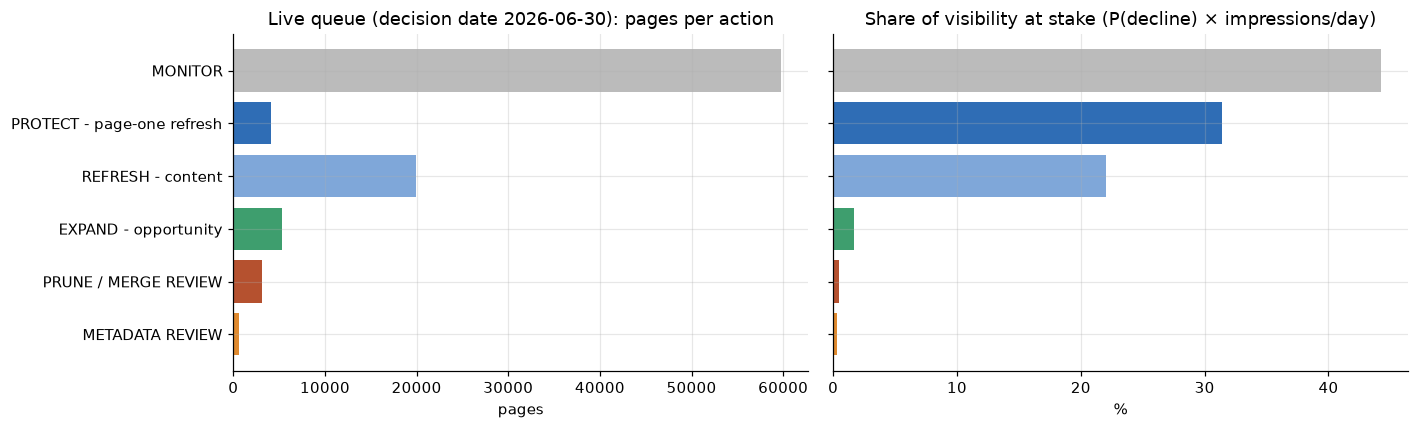

,pages,median_risk,median_impressions_per_day,share_of_visibility_at_stake
action,,,,
MONITOR,59740,0.246,23.088,0.442
PROTECT - page-one refresh,4127,0.856,182.165,0.314
REFRESH - content,19960,0.804,15.533,0.220
EXPAND - opportunity,5313,0.081,28.758,0.016
PRUNE / MERGE REVIEW,3160,0.814,5.044,0.005
METADATA REVIEW,632,0.815,7.308,0.003


,queue_rank,page,content_type,action,confidence,p_decline,imp_per_day_90,pos_90,mom_vs_site,reason_codes
445540,1.0,0e03de76…,keyword article,PROTECT - page-one refresh,medium,0.843,6218.824,2.452,0.610,SLIDING_VS_SITE;PAGE_ONE;HIGH_VISIBILITY
483558,2.0,77276ad7…,keyword article,PROTECT - page-one refresh,medium,0.814,5547.242,5.030,0.578,SLIDING_VS_SITE;POSITION_WORSENING;PAGE_ONE;HI...
461379,3.0,39e19a3e…,keyword article,PROTECT - page-one refresh,high,0.987,4208.209,9.795,0.043,SLIDING_VS_SITE;LATE_MONTH_SLIDE;POSITION_WORS...
524632,4.0,e7b5dd4d…,keyword article,PROTECT - page-one refresh,medium,0.700,5677.670,5.482,0.657,SLIDING_VS_SITE;LATE_MONTH_SLIDE;POSITION_WORS...
446861,5.0,11bf4c33…,keyword article,PROTECT - page-one refresh,high,0.938,3667.165,8.442,0.918,LATE_MONTH_SLIDE;PAGE_ONE;HIGH_VISIBILITY
448050,6.0,15168cd1…,keyword article,PROTECT - page-one refresh,medium,0.858,3863.132,3.651,0.694,SLIDING_VS_SITE;LATE_MONTH_SLIDE;PAGE_ONE;HIGH...
469344,7.0,4ffe1811…,keyword article,PROTECT - page-one refresh,high,0.901,3663.385,2.194,0.388,SLIDING_VS_SITE;PAGE_ONE;HIGH_VISIBILITY
496414,8.0,99fc6465…,keyword article,REFRESH - content,high,0.977,3121.813,10.245,0.004,SLIDING_VS_SITE;LATE_MONTH_SLIDE;POSITION_WORS...
495014,9.0,9648c4d1…,keyword article,PROTECT - page-one refresh,high,0.942,2996.659,2.341,0.078,SLIDING_VS_SITE;PAGE_ONE;HIGH_VISIBILITY
493042,10.0,9111c7d2…,keyword article,PROTECT - page-one refresh,high,0.878,2848.407,7.753,0.428,SLIDING_VS_SITE;LATE_MONTH_SLIDE;PAGE_ONE;HIGH...


In [17]:
m_all = ~D.is_live.values
live_model = clone(candidates[best_name]).fit(F.loc[m_all, FEATURES], y[m_all])
p_live = live_model.predict_proba(F.loc[m_live, FEATURES])[:, 1]
QL = build_queue(m_live, p_live)

# full queue for internal use (CSV is gitignored); paper-safe aggregates + top-20 with shortened IDs
QL.sort_values(["queue_rank", "p_decline"], ascending=[True, False]).to_csv(f"{OUT}/live_queue_2026-07.csv", index=False)
summary = (QL.groupby("action")
             .agg(pages=("p_decline", "size"), median_risk=("p_decline", "median"),
                  median_impressions_per_day=("imp_per_day_90", "median"),
                  share_of_visibility_at_stake=("visibility_at_stake", lambda s: s.sum() / QL.visibility_at_stake.sum()))
             .sort_values("share_of_visibility_at_stake", ascending=False))
summary.round(4).to_csv(f"{TAB}/live_queue_action_summary.csv")

top20 = QL.nsmallest(20, "queue_rank").copy()
top20["page"] = top20.content_hash_id.str.replace("content_", "").str[:8] + "…"
top20 = top20[["queue_rank", "page", "content_type", "action", "confidence", "p_decline", "imp_per_day_90",
               "pos_90", "mom_vs_site", "reason_codes"]]
top20.round(3).to_csv(f"{TAB}/live_queue_top20.csv", index=False)
codes_freq = (QL[QL.in_queue].reason_codes.str.split(";").explode().value_counts(normalize=True)
              .rename("share_of_queued_pages"))
codes_freq.round(4).to_csv(f"{TAB}/live_queue_reason_code_frequency.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = summary.index.tolist()
pal = {"PROTECT - page-one refresh": "#2F6DB5", "REFRESH - content": "#7FA7D9", "METADATA REVIEW": "#E08A2E",
       "PRUNE / MERGE REVIEW": "#B5512F", "EXPAND - opportunity": "#3E9E6E", "MONITOR": "#BBBBBB"}
axes[0].barh(order[::-1], summary.pages[::-1], color=[pal[a] for a in order[::-1]])
axes[0].set_title("Live queue (decision date 2026-06-30): pages per action"); axes[0].set_xlabel("pages")
axes[1].barh(order[::-1], summary.share_of_visibility_at_stake[::-1] * 100, color=[pal[a] for a in order[::-1]])
axes[1].set_title("Share of visibility at stake (P(decline) × impressions/day)"); axes[1].set_xlabel("%")
axes[1].set_yticklabels([])
fig.tight_layout(); fig.savefig(f"{FIG}/fig05_live_queue_actions.png", bbox_inches="tight"); plt.show()

RESULTS["live_queue"] = {"decision_date": CONFIG["live_decision_date"], "pages_scored": int(len(QL)),
                         "pages_in_queue": int(QL.in_queue.sum()),
                         "action_summary": summary.round(4).reset_index().to_dict(orient="records"),
                         "reason_code_frequency": codes_freq.round(4).to_dict()}
save_results()
display(summary.round(3))
top20.round(3)

**Reading the live queue.** Of 92,932 eligible pages, 27,879 (30%) enter the review queue. The **4,127 PROTECT pages** (4% of pages; median 182 impressions/day, median risk 0.86) carry **31% of all visibility at stake** — this is where an editor's first hours should go. REFRESH covers 20k smaller pages (22% of the stake); PRUNE/MERGE and METADATA are small hygiene buckets; MONITOR pages are individually low-risk but numerous, which is why they still sum to 44% of the stake. 5,313 growing pages are flagged as EXPAND opportunities.

The top 20 are all page-one, high-visibility keyword articles whose last month lagged their site (`SLIDING_VS_SITE`), most of them with a slide that continued into the second half of June (`LATE_MONTH_SLIDE`). Several of them (e.g. `39e19a3e…`, `15168cd1…`, `65c75874…`, `9648c4d1…`) were also at the top of my w04 baseline queue — the volume rule did find important pages, it just could not tell which of them were *still* sliding.

**The playbook in one paragraph (for the paper).** Each month, after the month closes: (1) score every visible page; (2) review PROTECT pages in queue order first — these are page-one pages losing ground faster than their site; check freshness, intent match and internal links, and change as little as possible; (3) work through REFRESH pages as capacity allows; (4) batch METADATA and PRUNE/MERGE reviews monthly; (5) hand EXPAND pages to whoever creates content; (6) treat a *site-wide* drop separately — this queue deliberately ignores it; (7) log what was changed so a later experiment can measure whether refreshes actually help.

## 7. Artifacts the paper embeds

Everything the deployed paper and the reportlab PDF need is in `work/outputs/capstone/`:
- `capstone_results.json` — every headline number quoted in the text (plus config, seeds, split sizes, leakage checks) — **committed** as the receipt;
- `figures/*.png` — the five charts;
- `tables/*.csv` — the small aggregate tables (gitignored like every CSV in `work/`; regenerated by this notebook);
- `paper_text.json` — abstract and section summaries in plain text for the PDF builder.

The cell below writes the paper text, builds a manifest, and runs a public-safety scan over everything that is meant to be published.

In [18]:
R, tt = RESULTS, test_tab.set_index("model")
mp, b2 = tt.loc["model — probability"], tt.loc["B2 site-relative momentum rule"]
mi_ = tt.loc["model — expected impact"]
abstract = (
    "Which visible pages should a content editor review first, before they lose search visibility? "
    f"Using the FlyRank pseudonymized warehouse release ({R['data_counts']['fact_daily_rows']:,} daily rows, 27 Jan 2025 to 30 Jun 2026), "
    "we built a monthly page panel and labelled a page as declining when its next-month daily impressions fell more than 20% "
    "below the median page of its own site, so that site-wide shocks are not mistaken for page decay. "
    "A histogram gradient-boosting model using only information available at the decision date was selected on May 2026 "
    f"and evaluated once on a sealed June 2026 month ({R['test']['rows']:,} pages, base rate {R['test']['base_rate']:.1%}), "
    f"reaching PR-AUC {mp['PR-AUC']:.3f} versus {b2['PR-AUC']:.3f} for the best transparent momentum rule "
    f"(gap +{R['test']['prauc_gap_vs_B2']['mean']:.3f}, 95% client-bootstrap CI +{R['test']['prauc_gap_vs_B2']['ci95'][0]:.3f} to +{R['test']['prauc_gap_vs_B2']['ci95'][1]:.3f}), "
    f"while an impact-ordered version of the score covers {mi_['lost_imp_captured@top10%']:.0%} of site-relative lost impressions in its top 10% of pages. "
    "The output is a ranked, reason-coded review queue for decision support; it does not show that refreshing a page causes recovery."
)
paper_text = {
    "title": "Which pages should an editor review first? A time-aware, site-relative decline-risk queue for content refresh",
    "abstract": abstract,
    "introduction": ("Editors have limited review hours; ~90k visible pages per month need triage. "
                     "The decision supported: which pages enter next month's review queue, with what action and why."),
    "key_findings": [
        f"Absolute decline label swings from 5% to 79% with site-wide shocks; the site-relative label is stable at 31–40%.",
        f"Sealed test: model PR-AUC {mp['PR-AUC']:.3f} / ROC-AUC {mp['ROC-AUC']:.3f} vs B2 rule {b2['PR-AUC']:.3f} / {b2['ROC-AUC']:.3f}.",
        f"On unseen clients the gap over B2 shrinks to +{R['limitations']['unseen_client_prauc_gap_vs_B2']:.3f} PR-AUC.",
        "The w04 volume rule ranks worse than chance for site-relative decline (ROC-AUC 0.38) but finds high-stake pages.",
        "Score drivers are momentum signals (page vs. site trend, late-month slide) — observed associations, not ranking factors.",
        f"Queue back-test: PROTECT pages (5% of pages) held {R['queue_backtest']['by_action'][[a['action'] for a in R['queue_backtest']['by_action']].index('PROTECT - page-one refresh')]['share_of_lost_impressions']:.0%} of site-relative lost impressions.",
    ],
    "acknowledgment": "Built on the FlyRank ML Internship dataset (https://flyrank.ai).",
    "claims_language": "observed / measured / directional / decision-support",
}
json.dump(paper_text, open(f"{OUT}/paper_text.json", "w"), indent=2)
RESULTS["abstract"] = abstract
save_results()

# manifest of everything produced
manifest = []
for folder in [OUT, FIG, TAB]:
    for fn in sorted(os.listdir(folder)):
        pth = os.path.join(folder, fn)
        if os.path.isfile(pth):
            manifest.append({"path": pth, "kb": round(os.path.getsize(pth) / 1024, 1)})
manifest = pd.DataFrame(manifest)
manifest.to_csv(f"{OUT}/manifest.csv", index=False)

# public-safety scan: publishable files must not contain client IDs, URLs (other than flyrank.ai) or full content IDs
import re
publishable = [p for p in manifest.path if not p.endswith("live_queue_2026-07.csv") and "/cache/" not in p
               and p.endswith((".csv", ".json"))]
issues = []
for pth in publishable:
    txt = open(pth).read()
    if "client_" in txt and re.search(r"client_[0-9a-f]{16}", txt): issues.append((pth, "client id"))
    if re.search(r"content_[0-9a-f]{16}", txt): issues.append((pth, "full content id"))
    for u in re.findall(r"https?://[^\s\"']+", txt):
        if "flyrank.ai" not in u: issues.append((pth, f"url {u}"))
print(f"{len(manifest)} files written; public-safety scan over {len(publishable)} publishable files -> "
      f"{'clean' if not issues else issues}")
assert not issues
print("\nABSTRACT\n" + abstract)
manifest

28 files written; public-safety scan over 22 publishable files -> clean

ABSTRACT
Which visible pages should a content editor review first, before they lose search visibility? Using the FlyRank pseudonymized warehouse release (78,835,655 daily rows, 27 Jan 2025 to 30 Jun 2026), we built a monthly page panel and labelled a page as declining when its next-month daily impressions fell more than 20% below the median page of its own site, so that site-wide shocks are not mistaken for page decay. A histogram gradient-boosting model using only information available at the decision date was selected on May 2026 and evaluated once on a sealed June 2026 month (89,237 pages, base rate 39.6%), reaching PR-AUC 0.724 versus 0.683 for the best transparent momentum rule (gap +0.041, 95% client-bootstrap CI +0.021 to +0.067), while an impact-ordered version of the score covers 66% of site-relative lost impressions in its top 10% of pages. The output is a ranked, reason-coded review queue for decision s

,path,kb
0,work/outputs/capstone/capstone_results.json,16.7
1,work/outputs/capstone/live_queue_2026-07.csv,21117.3
2,work/outputs/capstone/manifest.csv,1.6
3,work/outputs/capstone/paper_text.json,2.1
4,work/outputs/capstone/figures/fig01_label_base...,190.2
5,work/outputs/capstone/figures/fig02_test_ranki...,287.6
6,work/outputs/capstone/figures/fig03_test_metri...,79.4
7,work/outputs/capstone/figures/fig04_permutatio...,93.1
8,work/outputs/capstone/figures/fig05_live_queue...,84.9
9,work/outputs/capstone/tables/data_monthly_volu...,0.8


## Reproducibility

```bash
git clone https://github.com/Thallysson100/FlyRank_AI && cd FlyRank_AI
python -m venv venv && venv/bin/pip install -r requirements.txt duckdb ipykernel nbconvert
echo "HF_TOKEN=<your read token>" > .env          # never commit this file (.env is gitignored)
venv/bin/jupyter nbconvert --to notebook --execute --inplace work/notebooks/capstone.ipynb
```
- First run: one full scan of the 18 monthly partitions over `hf://` (~10 minutes), cached to `work/outputs/capstone/cache/*.parquet`; later runs read the cache only (~6 minutes end to end, dominated by model fits).
- Seed `42` everywhere (`numpy`, model `random_state`, bootstrap, permutation importance). Library versions are printed in §0.
- The sealed-test evidence is checkable from the repo: §4.2 builds the June frame and `capstone_results.json → test` holds the metrics it produced (`"evaluated_once": true`).

## Acknowledgments & data credit

Built on the **FlyRank ML Internship dataset** — [flyrank.ai](https://flyrank.ai). All identifiers are pseudonymized; no client names, domains, URLs or queries appear in this work.

## ML-12 — Demo, social post, employer summary

**5-minute demo outline**
1. *(0:00–0:40)* The problem: ~90k visible pages a month, a few review hours. Which pages first?
2. *(0:40–1:40)* The trap I fell into: an absolute "decline" label is 79% positive in June because the whole panel dropped. Show fig01 → switch to a site-relative label (stable 31–40%).
3. *(1:40–2:40)* Honest validation: decision dates, features only from the past, sealed June month, leakage checks (shuffled labels ≈ 0.5), and my old w05 model's inflated 0.995 AUC explained.
4. *(2:40–3:40)* Results: fig03 — model vs momentum rule (+0.041 PR-AUC, CI excludes 0); impact ordering catches 66% of lost impressions in 10% of pages; unseen clients shrink the gain.
5. *(3:40–4:40)* The playbook: fig05 + the top-20 table — PROTECT / REFRESH / METADATA / PRUNE / EXPAND with reason codes.
6. *(4:40–5:00)* Limits: no causality, one test month, monthly cadence misses sudden collapses.

**Social-post cut**
> I spent my FlyRank ML internship capstone on one question: which pages should an editor review first before they lose search visibility? The biggest lesson wasn't the model — it was the label. "Down 20%" was true for 79% of pages in my test month because the whole panel dropped. Measuring each page against its own site fixed that. Final result on a sealed future month: a gradient-boosting queue beat the best simple rule (PR-AUC 0.72 vs 0.68), and ordering by visibility at stake covered 66% of lost impressions in 10% of pages. Decision support, not magic — and on brand-new sites the simple rule is nearly as good. Built on the FlyRank ML Internship dataset (flyrank.ai).

**Employer-facing summary (3 sentences)**
I built an end-to-end, leakage-audited ranking system on a 79M-row search-performance warehouse, using DuckDB to aggregate remote Parquet and scikit-learn for time-aware, client-grouped validation. I caught and fixed two silent failure modes — a label dominated by site-wide shocks and an eligibility rule leaking into an earlier model — and reported a modest but bootstrap-verified gain over a strong transparent baseline, including where it does *not* hold. The result is a reason-coded editorial review queue with a back-tested policy, framed strictly as decision support.

## Self-check

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere (automated scan in §7; only shortened pseudonymous page IDs are shown)
- [x] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom *(paper/PDF not built yet)*
- [x] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary